# CUAD Class Imbalance & Category Selection Analysis

Purpose: Building on the class imbalance analysis of the 41 CUAD clause categories, we are narrowing the intial modeling scope to a smaller set of categories that have stronger data support and important contract-risk areas.

Goals:
1. **Understand the category**
   - Write a short definition and note what risk or obligation it represents.

2. **Check data support**
   - Record train positives, test positives, and overall prevalence.
   - Flag categories with very little data (high class imbalance).

3. **Inspect examples**
   - Review 5–10 positive examples with surrounding context.
   - Note whether annotations look consistent.

4. **Check clause structure**
   - Is it short or long?
   - One sentence or multiple paragraphs?
   - Does it need surrounding context?
   - Does it appear multiple times?

5. **Check overlap**
   - Note categories that look similar, overlap, or often appear together.

6. **Check cleaning issues**
   - Look for weird spacing, broken lines, formatting, punctuation, or other text issues.

7. **Think about chunking**
   - Could the clause be split across chunks?
   - Would overlap or extra context be needed?

# Installations

In [ ]:
!pip install -q datasets huggingface_hub

In [ ]:
from huggingface_hub import hf_hub_download
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#downloading cuad json from hugging face

json_path = hf_hub_download(
    repo_id="theatticusproject/cuad",
    filename="CUAD_v1/CUAD_v1.json",
    repo_type="dataset"
)

print(json_path)

/root/.cache/huggingface/hub/datasets--theatticusproject--cuad/snapshots/a3c393f5d103fd0c516374e4fdff676c8176dcb1/CUAD_v1/CUAD_v1.json


In [ ]:
#loading dataset

with open(json_path, "r") as f:
    cuad = json.load(f)

print(cuad.keys())

dict_keys(['version', 'data'])


Naeem & Amanda - Baseline Model & Initial Risk Rules

# Parse JSON to DF

In [ ]:
import re
def to_dataframe(cuad, split_name):
  '''
  Takes cuad JSON data and turns it into dataframe.

  Params:
    cuad: cuad JSON data
    split_name: str, represents the train/test/all split of the data

  Returns:
    pd.DataFrame
  '''
  rows = []
  for doc in cuad['data']:
      title = doc['title']
      for para in doc['paragraphs']:
          context_len = len(para['context'])
          for qa in para['qas']:
              category = qa['id'].split('__', 1)[1] if '__' in qa['id'] else None

              if category is not None:
                  category = re.sub(r"_\d+$", "", category)
              answers = qa.get('answers', [])
              rows.append({
                  'split': split_name,
                  'contract_title': title,
                  'category': category,
                  'question': qa['question'],
                  'qa_id': qa['id'],
                  'is_impossible': qa.get('is_impossible', False),
                  'num_answers': len(answers),
                  'answer_texts': [a['text'] for a in answers],
                  'answer_starts': [a['answer_start'] for a in answers],
                  'context_length': context_len,
              })
  return pd.DataFrame(rows)

In [ ]:
df_full = to_dataframe(cuad, 'full')
df_full.head()

,split,contract_title,category,question,qa_id,is_impossible,num_answers,answer_texts,answer_starts,context_length
0,full,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Document Name,Highlight the parts (if any) of this contract ...,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,False,1,[DISTRIBUTOR AGREEMENT],[44],54290
1,full,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,Highlight the parts (if any) of this contract ...,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,False,5,"[Distributor, Electric City Corp., Electric Ci...","[244, 148, 49574, 197, 212]",54290
2,full,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Agreement Date,Highlight the parts (if any) of this contract ...,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,False,1,"[7th day of September, 1999.]",[263],54290
3,full,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Effective Date,Highlight the parts (if any) of this contract ...,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,False,2,[The term of this Agreement shall be ten (10...,"[5268, 31058]",54290
4,full,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Expiration Date,Highlight the parts (if any) of this contract ...,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,False,1,[The term of this Agreement shall be ten (10...,[5268],54290


In [ ]:
df_full["has_clause"] = ~df_full["is_impossible"].astype(bool)

## Find Class Imbalance
Creates a dataframe that orders the most imbalanced to least imbalanced class by ratio.

High imbalance is defined by either most contracts containing the clause or most not containing the clause. Low imbalance is when there is a roughly equal number of contracts containing and not containing the clause.

In [ ]:
imb = df_full.groupby("category")["has_clause"].agg(n="size", positives="sum")
imb["negatives"] = imb["n"] - imb["positives"]
imb["pos_rate"] = imb["positives"] / imb["n"]
imb["minority_class"] = np.where(imb["pos_rate"] < 0.5, "present", "absent")
imb["minority_share"] = np.minimum(imb["pos_rate"], 1 - imb["pos_rate"])
imb["imbalance_ratio"] = (np.maximum(imb["positives"], imb["negatives"]) /
                          np.minimum(imb["positives"], imb["negatives"]).replace(0, np.nan))
imb = imb.sort_values("minority_share")

print("15 MOST imbalanced categories:")
display(imb.head(15)[["n", "positives", "negatives", "pos_rate",
                      "minority_class", "imbalance_ratio"]].round(3))
print()
print("5 LEAST imbalanced categories:")
display(imb.tail(5)[["n", "positives", "negatives", "pos_rate", "imbalance_ratio"]].round(3))

15 MOST imbalanced categories:


,n,positives,negatives,pos_rate,minority_class,imbalance_ratio
category,,,,,,
Document Name,510,510,0,1.000,absent,NaN
Parties,510,509,1,0.998,absent,509.000
Source Code Escrow,510,13,497,0.025,present,38.231
Price Restrictions,510,15,495,0.029,present,33.000
Unlimited/All-You-Can-Eat-License,510,17,493,0.033,present,29.000
Affiliate License-Licensor,510,23,487,0.045,present,21.174
Most Favored Nation,510,28,482,0.055,present,17.214
Third Party Beneficiary,510,32,478,0.063,present,14.938
No-Solicit Of Customers,510,34,476,0.067,present,14.000



5 LEAST imbalanced categories:


,n,positives,negatives,pos_rate,imbalance_ratio
category,,,,,
Post-Termination Services,510,182,328,0.357,1.802
Termination For Convenience,510,183,327,0.359,1.787
Audit Rights,510,214,296,0.420,1.383
Cap On Liability,510,275,235,0.539,1.170
License Grant,510,255,255,0.500,1.000


## Graph Class Imbalance

This is simply a visualization of the data in the table above.

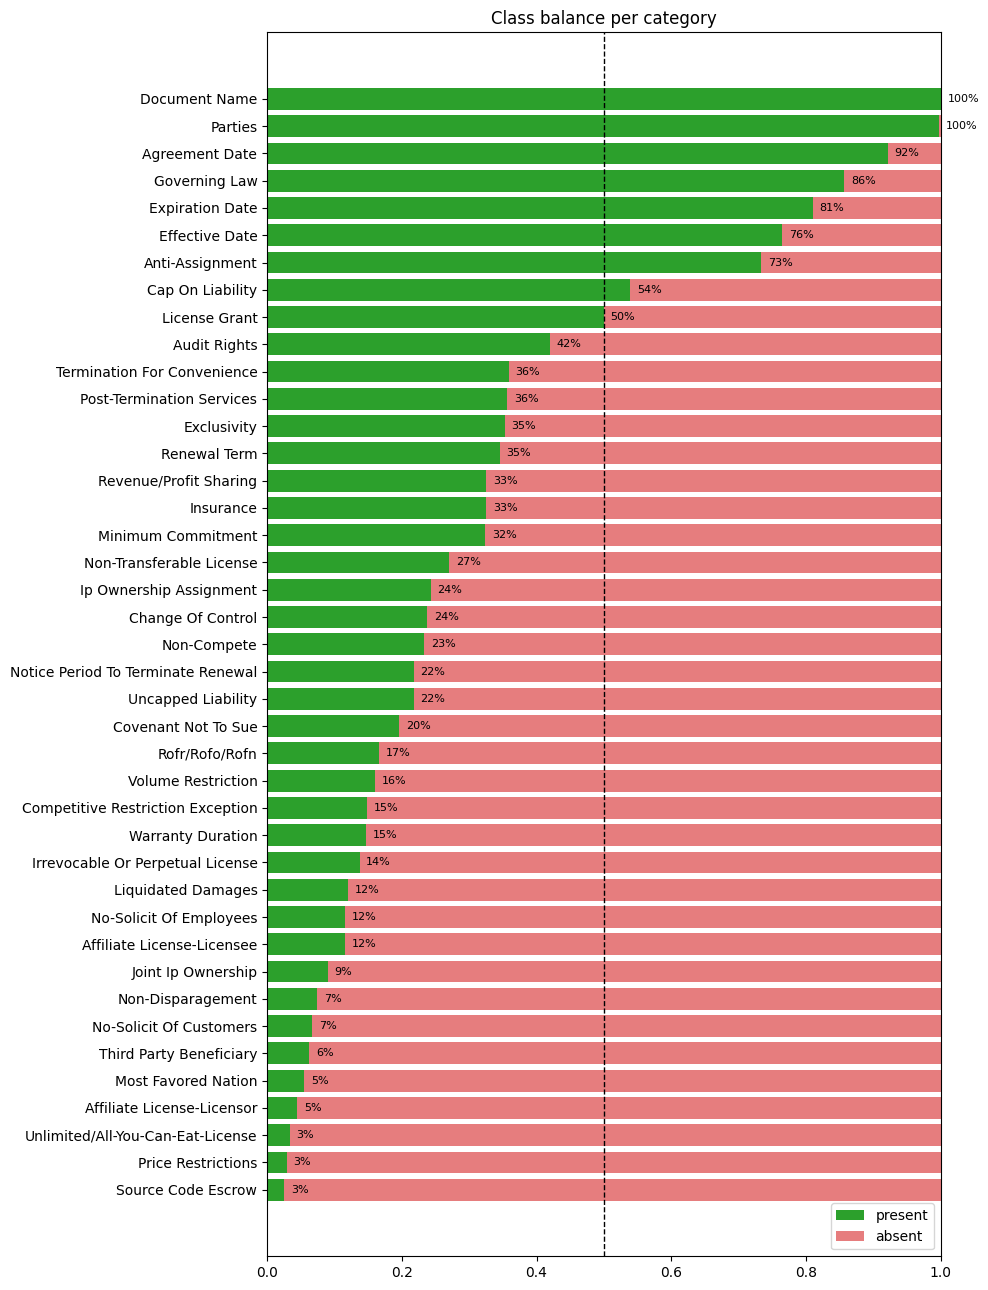

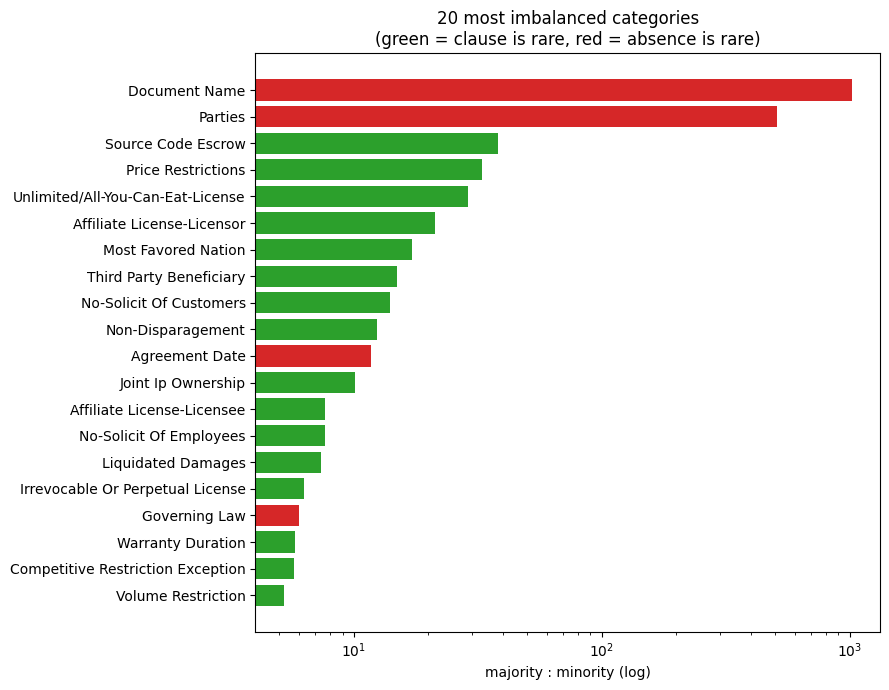

In [ ]:
p = imb.sort_values("pos_rate")
fig, ax = plt.subplots(figsize=(10, 13))
ax.barh(p.index, p["pos_rate"], color="tab:green", label="present")
ax.barh(p.index, 1 - p["pos_rate"], left=p["pos_rate"], color="tab:red", alpha=0.6, label="absent")
ax.axvline(0.5, color="black", ls="--", lw=1)
for i, v in enumerate(p["pos_rate"]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8)
ax.set_xlim(0, 1)
ax.set_title("Class balance per category")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

top = imb.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top["imbalance_ratio"].fillna(top["imbalance_ratio"].max() * 2),
        color=top["minority_class"].map({"present": "tab:green", "absent": "tab:red"}))
ax.set_xscale("log")
ax.set_xlabel("majority : minority (log)")
ax.set_title("20 most imbalanced categories\n(green = clause is rare, red = absence is rare)")
plt.tight_layout(); plt.show()

## Graph average length of the answer

The box plots show how many words in a chunk it would take for a model to deduce whether or not the specific clause is present. For instance, dates take very few words to detect (month, day, year) while a model may need more text to detect non-competes due to technical terminology.

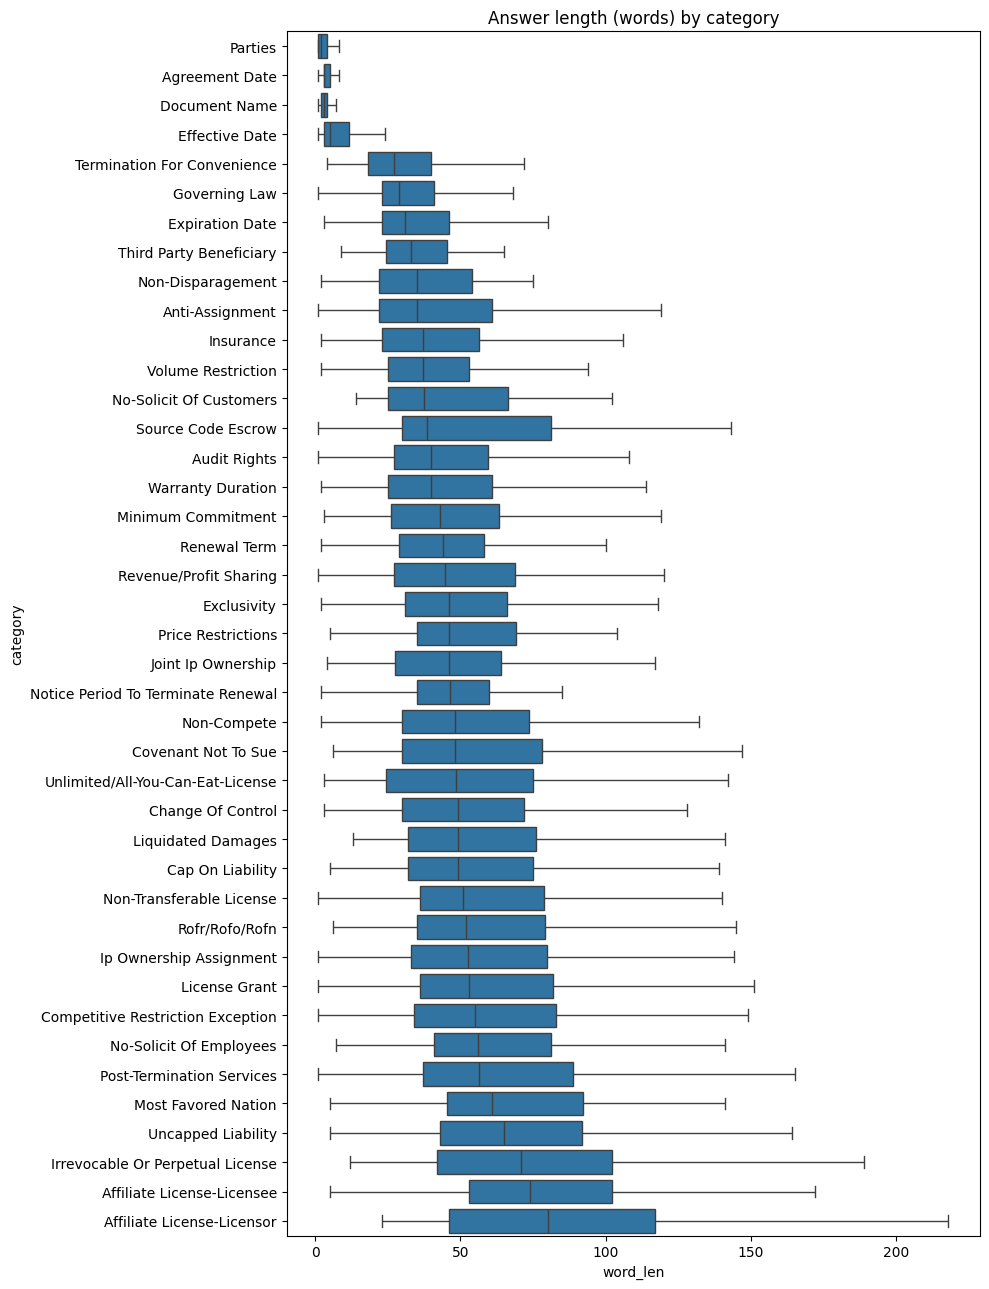

In [ ]:
pos = df_full[df_full["has_clause"]]
spans = pos[["category", "answer_texts"]].explode("answer_texts").dropna()
spans["word_len"] = spans["answer_texts"].str.split().str.len()
order = spans.groupby("category")["word_len"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 13))
sns.boxplot(data=spans, y="category", x="word_len", order=order, showfliers=False, ax=ax)
ax.set_title("Answer length (words) by category")
plt.tight_layout(); plt.show()

## Graph Contract Length

This graph shows the distribution of how long contracts are and can help guide chunking decisions.

count       510.0
mean      52563.0
std       55946.0
min         645.0
25%       16416.0
50%       33143.0
75%       66395.0
max      338211.0


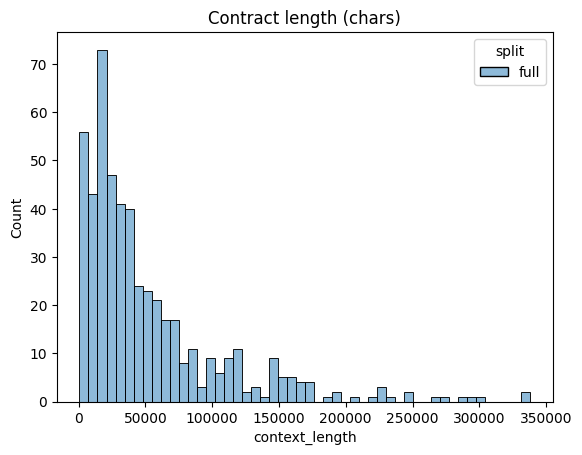

In [ ]:
contracts = df_full.drop_duplicates(["split", "contract_title"])[["split", "contract_title", "context_length"]]
print(contracts["context_length"].describe().round(0).to_string())

sns.histplot(data=contracts, x="context_length", hue="split", bins=50)
plt.title("Contract length (chars)"); plt.show()

## Graph of where clauses appear in the contract.

This can guide roughly where in the contract we should expect the model to draw from based on which clause it is trying to detect for.

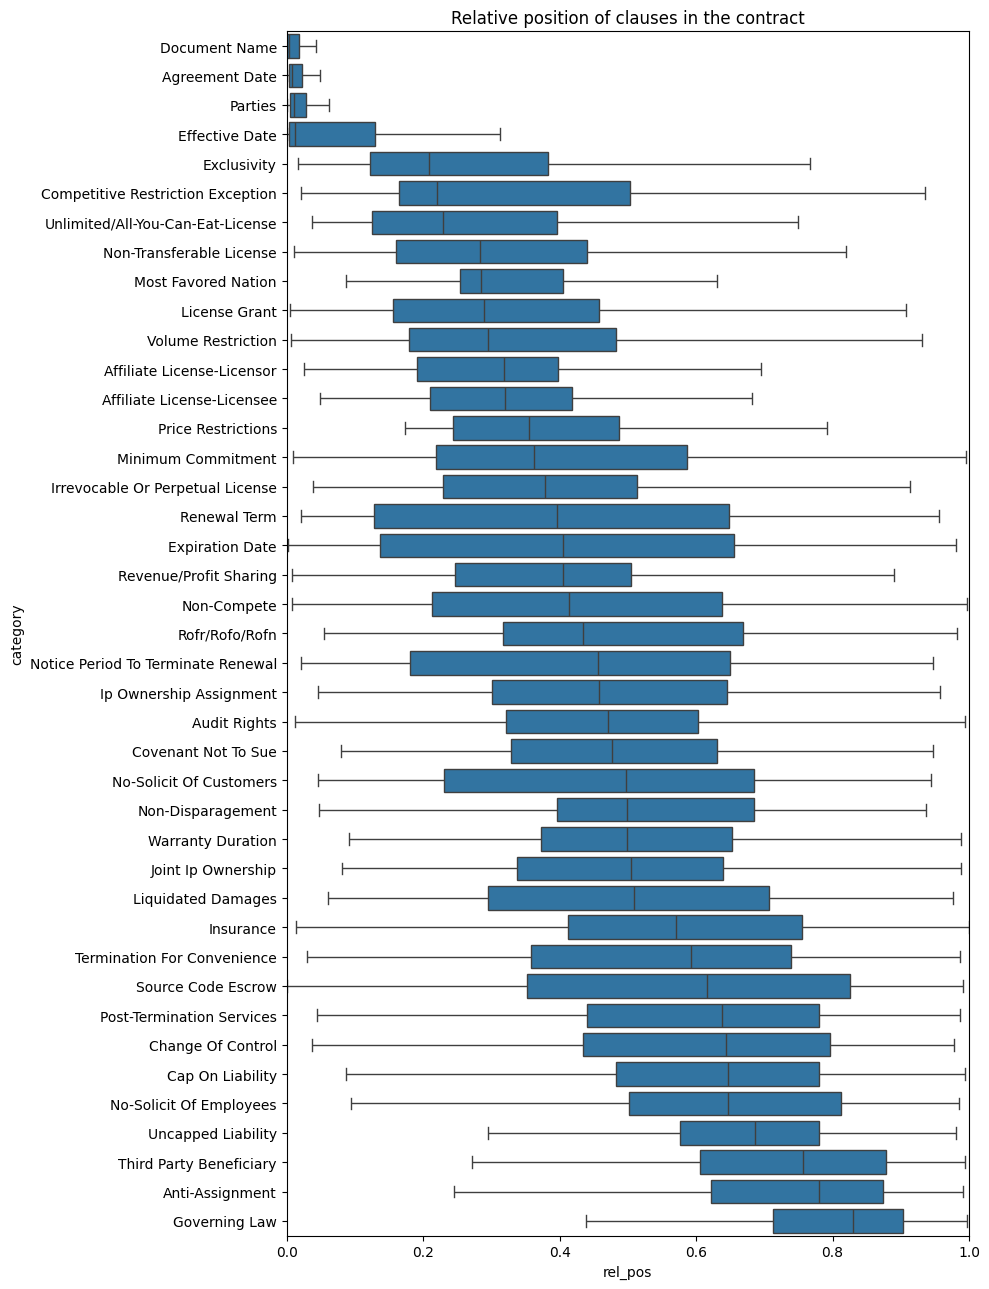

In [ ]:
starts = pos[["category", "answer_starts", "context_length"]].explode("answer_starts").dropna()
starts["rel_pos"] = starts["answer_starts"].astype(int) / starts["context_length"]
order = starts.groupby("category")["rel_pos"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 13))
sns.boxplot(data=starts, y="category", x="rel_pos", order=order, showfliers=False, ax=ax)
ax.set_xlim(0, 1)
ax.set_title("Relative position of clauses in the contract")
plt.tight_layout(); plt.show()

## Heatmap of how related each clause is to another.

Clauses that are too similar may not need to be all included in the feature set, as one can almost imply the presence of another.

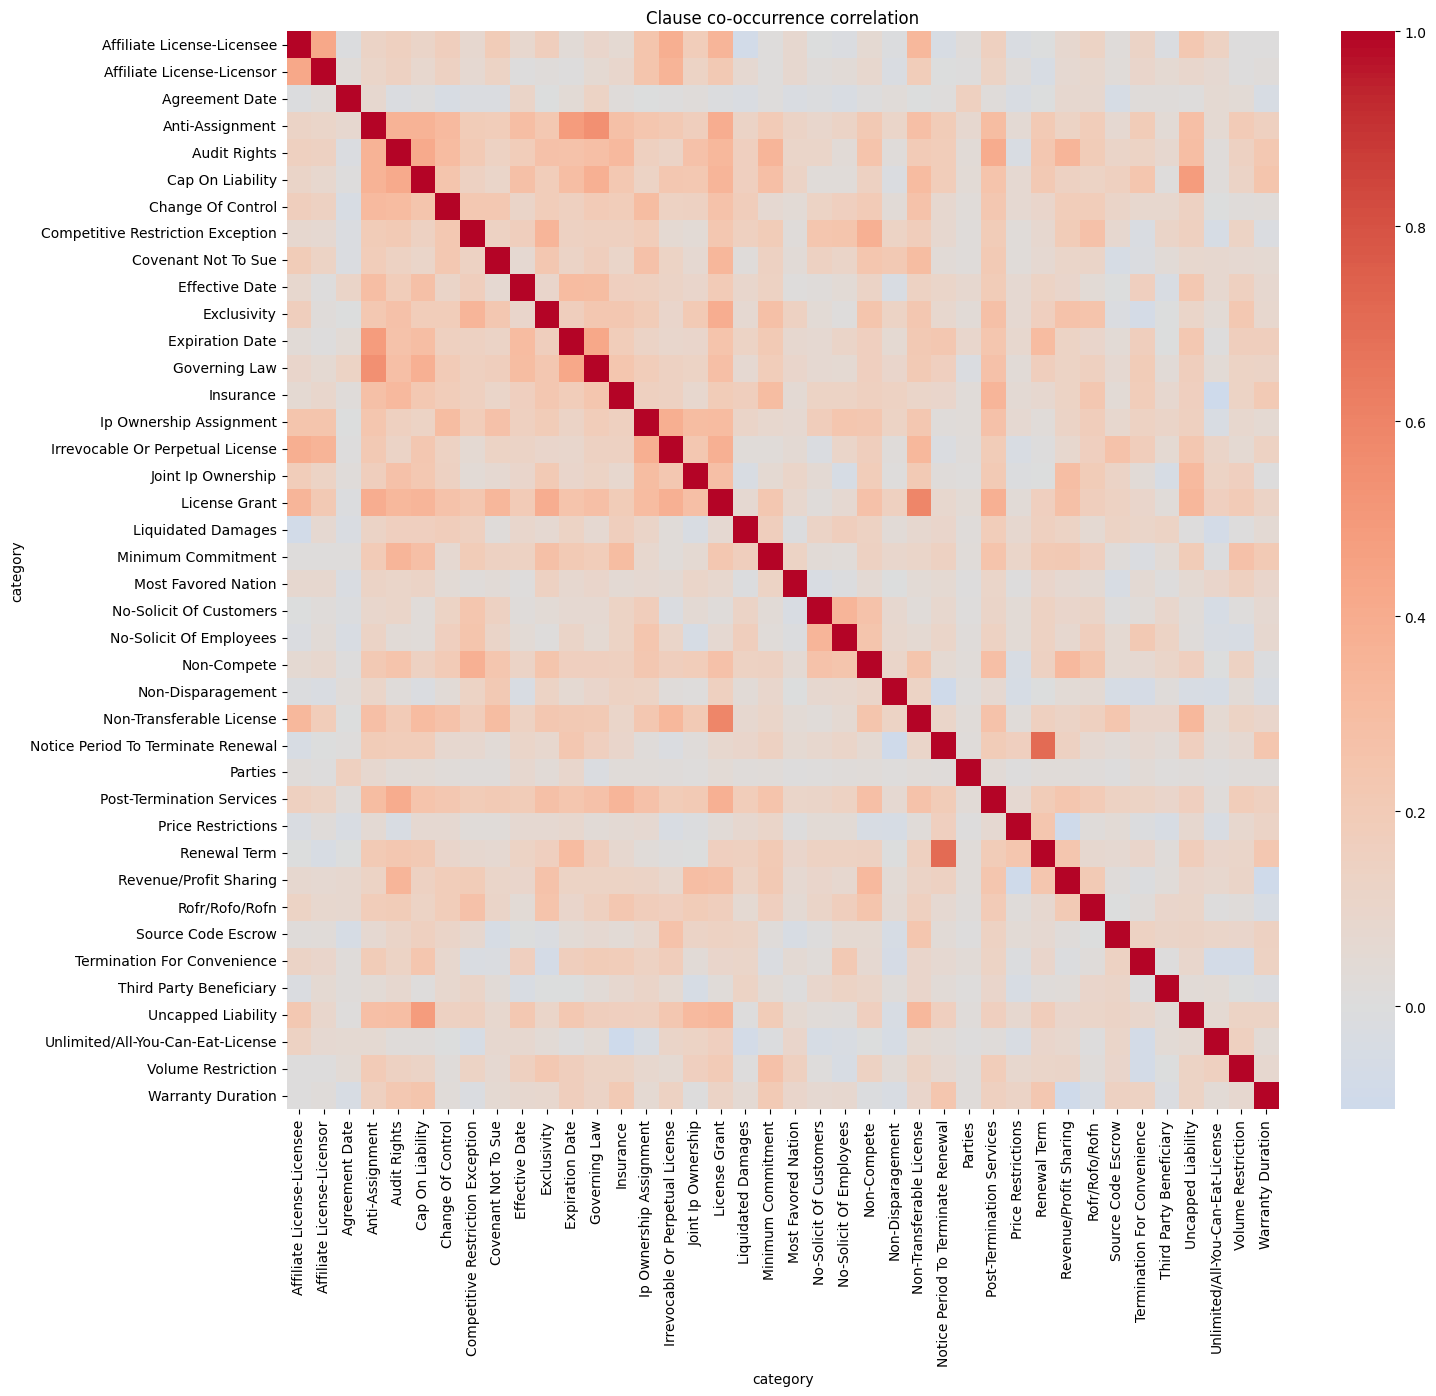

In [ ]:
presence = df_full.pivot_table(index="contract_title", columns="category", values="has_clause", aggfunc="max")

corr = presence.loc[:, presence.std() > 0].corr()
plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Clause co-occurrence correlation");
plt.show()

# Individual Category Review

# Jasmin — Anti-Assignment & Change of Control EDA

In [ ]:
import textwrap

def review_category(category, num_examples=7):

    category_df = df_full[
        df_full["category"] == category
    ].copy()

    positive_df = category_df[
        category_df["num_answers"] > 0
    ].reset_index(drop=True)

    print("Category:", category)
    print("Total contracts:", len(category_df))
    print("Positive contracts:", len(positive_df))
    print("Negative contracts:", (category_df["num_answers"] == 0).sum())

    if len(category_df) > 0:
        print(
            "Positive rate:",
            round(len(positive_df) / len(category_df) * 100, 1),
            "%"
        )

    print()

    for i in range(min(num_examples, len(positive_df))):
        row = positive_df.iloc[i]

        print("=" * 100)
        print("CONTRACT:", row["contract_title"])
        print("NUMBER OF ANSWERS:", row["num_answers"])

        for j, answer in enumerate(row["answer_texts"], start=1):
            print(f"\nAnswer {j}:")
            print(textwrap.fill(" ".join(answer.split()), width=100))

        print()

## Anti-Assignment EDA

In [ ]:
review_category("Anti-Assignment")

Category: Anti-Assignment
Total contracts: 510
Positive contracts: 374
Negative contracts: 136
Positive rate: 73.3 %

CONTRACT: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
NUMBER OF ANSWERS: 2

Answer 1:
No assignment of this Agreement or any right accruing hereunder shall be made by the Distributor in
whole or in part, without the prior written consent of the Company, which consent shall not be
unreasonably withheld.

Answer 2:
In the event either party (a) becomes adjudicated insolvent, (b) discontinues its business, (c) has
voluntary of involuntary bankruptcy proceedings instituted against it, or (d) makes an assignment
for the benefit of creditors, the other party shall be entitled to terminate this Agreement
effective immediately upon written notice.

CONTRACT: WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION AND DISTRIBUTION AGREEMENT
NUMBER OF ANSWERS: 1

Answer 1:
[ * ] may [ * ]any of its rights or obligations under this Agreement without the prior written
consent of [ * ]

### Anti-Assignment — Notes

### Class Imbalance
- Positive: 374
- Negative: 136
- Positive rate: 73.3%
- The category is moderately imbalanced toward the positive class.
- This is not a severe imbalance, but accuracy alone could still be misleading.
- Use per-category precision, recall, and F1 when evaluating performance.

### Common Patterns
- Common wording:
  - "may not be assigned"
  - "assign or transfer"
  - "rights or obligations"
  - "without prior written consent"
- Some examples also mention subcontracting, delegation, or sublicensing.

### Context / Chunking
- Longer clauses often contain exceptions for affiliates, mergers, stock sales, or successors.
- Keep the restriction and its exceptions in the same chunk when possible.
- Overlap may help prevent splitting important conditions.

### Key Issues
- Redactions like `[ * ]` and `[***]` create unusual formatting.
- Some examples are broader than a simple assignment restriction.
- Strong overlap with **Change Of Control**, especially around mergers and ownership changes.

## Change of Control EDA

In [ ]:
review_category("Change Of Control")

Category: Change Of Control
Total contracts: 510
Positive contracts: 121
Negative contracts: 389
Positive rate: 23.7 %

CONTRACT: WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION AND DISTRIBUTION AGREEMENT
NUMBER OF ANSWERS: 4

Answer 1:
[ * ] expected to experience, or [ * ] is experiencing, such Change of Control shall notify [ * ] in
writing of this before or within [ * ] after the Change of Control.

Answer 2:
[ * ] may terminate this Agreement immediately upon written notice if there is a Change of Control
of [ * ]. In this Clause the term "Control" shall mean the possession by any person(s) directly or
indirectly of the power to direct or cause the direction of another person and "Change of Control"
is to be construed accordingly.

Answer 3:
For the avoidance of doubt, if following [ * ] there is a transfer of shareholding or interests in
Distributor to any existing or new shareholder(s) which results in any person or persons
subsequently gaining Control of Distributor, then Google m

### Change Of Control — Notes

### Class Imbalance
- Positive: 121
- Negative: 389
- Positive rate: 23.7%
- Noticeably imbalanced toward the negative class.
- This is not extremely rare, but the model will still see about 3x more negatives than positives.
- Precision, recall, and F1 will be more useful than accuracy alone.

### Common Patterns
- Common wording:
  - "Change of Control"
  - merger / consolidation
  - sale or transfer of assets
  - change in shareholding
  - successor / buyer
- A Change Of Control can trigger termination, consent requirements, repayment, or limits on rights/licenses.

### Context / Chunking
- Often more context-dependent than Anti-Assignment.
- Definitions, trigger events, and consequences may appear across several sentences.
- Chunking should try to keep together:
  - what counts as a Change Of Control
  - what event triggered it
  - what happens afterward

### Key Issues
- Redactions like `[ * ]` and `[**]` appear in some examples.
- Some examples do not explicitly use the phrase "Change of Control" and instead describe mergers, asset sales, or successors.
- Strong overlap with **Anti-Assignment**, since some contracts treat a Change Of Control as an assignment.
- Some annotated spans appear incomplete or are part of longer multi-sentence provisions.

# Barry — Category EDA & Cleaning Review

Assigned categories:

- **Insurance**
- **Notice Period To Terminate Renewal**
- **Renewal Term**

This section is separate from any teammate-specific category variables so it does not overwrite existing work.

The analysis below covers:

1. train/test prevalence,
2. answer-span length,
3. representative examples,
4. formatting/cleaning issues,
5. overlap between the renewal-related categories,
6. common wording/patterns,
7. multiple spans and outliers,
8. category-specific cleaning recommendations.

In [ ]:
train_json = {"data": cuad["data"][:408]}
test_json = {"data": cuad["data"][408:]}

In [ ]:
df_train = to_dataframe(train_json, "train")
df_test = to_dataframe(test_json, "test")

df_train["has_clause"] = ~df_train["is_impossible"].astype(bool)
df_test["has_clause"] = ~df_test["is_impossible"].astype(bool)

barry_categories = [
    "Insurance",
    "Notice Period To Terminate Renewal",
    "Renewal Term"
]

barry_categories

['Insurance', 'Notice Period To Terminate Renewal', 'Renewal Term']

In [ ]:
def aggregate_contract_category(df):
    return (
        df.groupby(
            ["split", "contract_title", "category"],
            as_index=False
        )
        .agg(
            has_clause=("has_clause", "max"),
            answer_texts=("answer_texts", lambda s: [a for lst in s for a in lst]),
            answer_starts=("answer_starts", lambda s: [a for lst in s for a in lst]),
        )
    )

df_train_cc = aggregate_contract_category(df_train)
df_test_cc = aggregate_contract_category(df_test)

print("Train rows:", len(df_train_cc))
print("Test rows:", len(df_test_cc))

Train rows: 16728
Test rows: 4182


## 1. Train/Test prevalence and clause length

In [ ]:
def category_split_summary(categories):
    if df_train_cc is None or df_test_cc is None:
        print("Official train/test files are not available.")
        return None

    rows = []
    for category in categories:
        train_cat = df_train_cc[df_train_cc["category"] == category]
        test_cat = df_test_cc[df_test_cc["category"] == category]

        spans = []
        for frame in [train_cat, test_cat]:
            for answers in frame.loc[frame["has_clause"], "answer_texts"]:
                spans.extend(answers)

        lengths = pd.Series([len(x.split()) for x in spans], dtype=float)

        rows.append({
            "category": category,
            "train_positive": int(train_cat["has_clause"].sum()),
            "train_total": len(train_cat),
            "train_positive_rate": train_cat["has_clause"].mean(),
            "test_positive": int(test_cat["has_clause"].sum()),
            "test_total": len(test_cat),
            "test_positive_rate": test_cat["has_clause"].mean(),
            "answer_spans": len(spans),
            "median_span_words": lengths.median(),
            "p95_span_words": lengths.quantile(0.95),
            "max_span_words": lengths.max(),
        })

    return pd.DataFrame(rows)

barry_summary = category_split_summary(barry_categories)
if barry_summary is not None:
    display(
        barry_summary.style.format({
            "train_positive_rate": "{:.1%}",
            "test_positive_rate": "{:.1%}",
            "median_span_words": "{:.1f}",
            "p95_span_words": "{:.1f}",
            "max_span_words": "{:.0f}",
        })
    )

,category,train_positive,train_total,train_positive_rate,test_positive,test_total,test_positive_rate,answer_spans,median_span_words,p95_span_words,max_span_words
0,Insurance,133,408,32.6%,33,102,32.4%,560,37.0,113.0,350
1,Notice Period To Terminate Renewal,90,408,22.1%,21,102,20.6%,122,46.5,84.9,156
2,Renewal Term,139,408,34.1%,37,102,36.3%,210,44.0,105.3,461


## 2. Representative positive examples

This reviews representative positive examples using the aggregated official train/test data, with one row per contract-category pair.

In [ ]:
def review_barry_category(category, num_examples=5):
    combined = pd.concat(
        [df_train_cc, df_test_cc],
        ignore_index=True
    )

    category_df = combined[
        combined["category"] == category
    ].copy()

    positive_df = category_df[
        category_df["has_clause"]
    ].reset_index(drop=True)

    print("Category:", category)
    print("Total contracts:", len(category_df))
    print("Positive contracts:", len(positive_df))
    print("Negative contracts:", len(category_df) - len(positive_df))
    print(
        "Positive rate:",
        round(len(positive_df) / len(category_df) * 100, 1),
        "%"
    )

    print()

    for i in range(min(num_examples, len(positive_df))):
        row = positive_df.iloc[i]

        print("=" * 100)
        print("CONTRACT:", row["contract_title"])
        print("NUMBER OF ANSWER SPANS:", len(row["answer_texts"]))

        for j, answer in enumerate(row["answer_texts"], start=1):
            print(f"\nAnswer {j}:")
            print(textwrap.fill(" ".join(answer.split()), width=100))

        print()


for category in barry_categories:
    print("\n" + "#" * 100)
    print(category)
    print("#" * 100)
    review_barry_category(category, num_examples=5)


####################################################################################################
Insurance
####################################################################################################
Category: Insurance
Total contracts: 510
Positive contracts: 166
Negative contracts: 344
Positive rate: 32.5 %

CONTRACT: ADAPTIMMUNETHERAPEUTICSPLC_04_06_2017-EX-10.11-STRATEGIC ALLIANCE AGREEMENT
NUMBER OF ANSWER SPANS: 2

Answer 1:
MD Anderson has and will maintain in force during the term of this Agreement adequate insurance or
financial resources to cover its obligations pursuant to this Agreement.

Answer 2:
During the term of any Study Order under this Agreement, Adaptimmune Limited shall maintain in full
force and effect insurance for its and Adaptimmune's liabilities arising from the Study with limits
of not less than $*** per loss and $*** annual aggregate. Adaptimmune shall provide MD Anderson with
evidence of such insurance upon request.

CONTRACT: AFSALABANCORPINC

## 3. Inspect raw formatting

The normal review helper may clean whitespace for readability. This cell intentionally shows the raw strings so formatting artifacts remain visible.


In [ ]:
def raw_examples(category, n=5):
    if df_train_cc is not None and df_test_cc is not None:
        source = pd.concat([df_train_cc, df_test_cc], ignore_index=True)
        source = source[(source["category"] == category) & source["has_clause"]]
        spans = [a for answers in source["answer_texts"] for a in answers]
    elif "df_full" in globals():
        source = df_full[(df_full["category"] == category) & df_full["has_clause"]]
        spans = [a for answers in source["answer_texts"] for a in answers]
    else:
        print("No usable dataframe found.")
        return

    print("CATEGORY:", category)
    for i, span in enumerate(spans[:n], 1):
        print(f"\nRaw example {i}:")
        print(repr(span))

for category in barry_categories:
    print("\n" + "=" * 100)
    raw_examples(category, 5)


CATEGORY: Insurance

Raw example 1:
'MD Anderson has and will maintain in force during the term of this Agreement adequate insurance or financial resources to cover its obligations pursuant to this Agreement.'

Raw example 2:
"During the term of any Study Order under this Agreement, Adaptimmune Limited shall maintain in full force and effect insurance for its and Adaptimmune's liabilities arising from the Study with limits of not less than $*** per loss and $*** annual aggregate. Adaptimmune shall provide MD Anderson with evidence of such insurance upon request."

Raw example 3:
'The  Association  is a  member  of the  FHLBNY,  and the deposit  accounts of the  Association  are insured by the FDIC up to the maximum amount  allowed  under  law  and to the  best  of such  counsel\'s  knowledge  no proceedings  for the  termination or revocation of such insurance are pending or threatened;  and the description of the liquidation  account as set forth in the Registration  Statement  and t

## 4. Formatting / cleaning issue counts

In [ ]:
def formatting_issue_summary(categories):
    if df_train_cc is not None and df_test_cc is not None:
        source = pd.concat([df_train_cc, df_test_cc], ignore_index=True)
    elif "df_full" in globals():
        source = df_full.copy()
    else:
        print("No usable dataframe found.")
        return None

    rows = []
    for category in categories:
        cat = source[(source["category"] == category) & source["has_clause"]]
        spans = [a for answers in cat["answer_texts"] for a in answers]

        rows.append({
            "category": category,
            "spans": len(spans),
            "contains_newline": sum("\n" in x for x in spans),
            "repeated_spaces": sum(bool(re.search(r" {2,}", x)) for x in spans),
            "nonbreaking_space": sum("\u00a0" in x for x in spans),
            "redaction_marker": sum("[***" in x or "*****" in x or "…***…" in x for x in spans),
        })

    return pd.DataFrame(rows)

barry_formatting = formatting_issue_summary(barry_categories)
if barry_formatting is not None:
    display(barry_formatting)

,category,spans,contains_newline,repeated_spaces,nonbreaking_space,redaction_marker
0,Insurance,560,29,98,0,43
1,Notice Period To Terminate Renewal,122,4,22,0,4
2,Renewal Term,210,6,44,0,9


## 5. Renewal Term vs. Notice Period To Terminate Renewal

These labels are related but represent different information:

- **Renewal Term** = how long / under what mechanism the agreement renews.
- **Notice Period To Terminate Renewal** = how much advance notice is required to stop that renewal.

A single provision can legitimately contain both.


In [ ]:
if df_train_cc is not None and df_test_cc is not None:
    combined_cc = pd.concat([df_train_cc, df_test_cc], ignore_index=True)

    presence = combined_cc.pivot_table(
        index=["split", "contract_title"],
        columns="category",
        values="has_clause",
        aggfunc="max",
        fill_value=False
    )

    display(pd.crosstab(
        presence["Renewal Term"],
        presence["Notice Period To Terminate Renewal"]
    ))

    def exact_shared_span_stats(raw_df):
        def span_sets(category):
            result = {}
            for _, row in raw_df[raw_df["category"] == category].iterrows():
                result.setdefault(row["contract_title"], set()).update(row["answer_texts"])
            return result

        renewal = span_sets("Renewal Term")
        notice = span_sets("Notice Period To Terminate Renewal")

        both_positive = 0
        exact_contracts = 0
        exact_spans = 0

        for contract in set(renewal) & set(notice):
            if renewal[contract] and notice[contract]:
                both_positive += 1
                shared = renewal[contract] & notice[contract]
                if shared:
                    exact_contracts += 1
                    exact_spans += len(shared)

        return both_positive, exact_contracts, exact_spans

    rows = []
    for split_name, raw_df in [("train", df_train), ("test", df_test)]:
        both, exact_contracts, exact_spans = exact_shared_span_stats(raw_df)
        rows.append({
            "split": split_name,
            "contracts_positive_for_both": both,
            "contracts_with_exact_same_span": exact_contracts,
            "exact_shared_spans": exact_spans,
        })

    display(pd.DataFrame(rows))
else:
    print("Official split files unavailable; overlap analysis skipped.")

Notice Period To Terminate Renewal,False,True
Renewal Term,,
False,332,2
True,67,109


,split,contracts_positive_for_both,contracts_with_exact_same_span,exact_shared_spans
0,train,88,73,78
1,test,21,16,19


## 6. Common wording / patterns

This checks common words in positive labeled spans for each assigned category. The goal is not aggressive NLP preprocessing, but to identify recurring language that should be preserved during cleaning.

In [ ]:
from collections import Counter

def top_words_for_category(df, category, n=20):
    cat = df[
        (df["category"] == category) &
        (df["has_clause"])
    ]

    spans = [
        answer
        for answers in cat["answer_texts"]
        for answer in answers
    ]

    words = []
    for text in spans:
        words.extend(re.findall(r"\b[a-zA-Z]+\b", text.lower()))

    stop_words = {
        "the", "and", "of", "to", "a", "in", "or",
        "this", "that", "for", "be", "by", "with",
        "as", "is", "shall", "such", "any", "an"
    }

    words = [word for word in words if word not in stop_words]

    return Counter(words).most_common(n)


for category in barry_categories:
    print("\n" + "=" * 100)
    print(category)
    print(top_words_for_category(df_train_cc, category))


Insurance
[('insurance', 673), ('liability', 353), ('at', 211), ('coverage', 194), ('agreement', 169), ('maintain', 155), ('its', 155), ('all', 152), ('s', 149), ('each', 149), ('party', 143), ('not', 133), ('will', 117), ('policy', 114), ('limits', 99), ('other', 98), ('policies', 97), ('including', 97), ('than', 96), ('provide', 96)]

Notice Period To Terminate Renewal
[('term', 194), ('agreement', 141), ('party', 110), ('initial', 83), ('renewal', 79), ('year', 78), ('unless', 77), ('notice', 76), ('prior', 74), ('automatically', 67), ('one', 65), ('at', 65), ('written', 65), ('either', 63), ('other', 62), ('days', 60), ('renew', 59), ('least', 48), ('date', 43), ('end', 42)]

Renewal Term
[('term', 276), ('agreement', 249), ('year', 126), ('party', 123), ('renewal', 116), ('initial', 99), ('renew', 93), ('automatically', 92), ('unless', 92), ('one', 87), ('notice', 82), ('prior', 76), ('at', 74), ('terms', 73), ('other', 72), ('written', 69), ('on', 64), ('additional', 63), ('eith

## 7. Multiple spans and outliers

Some contracts may contain multiple labeled spans for the same category, and some annotations are much longer than typical. This checks those cases because they may require more surrounding context and can affect chunking or preprocessing decisions.

In [ ]:
rows = []

for category in barry_categories:
    cat = df_train_cc[
        (df_train_cc["category"] == category) &
        (df_train_cc["has_clause"])
    ].copy()

    cat["num_spans"] = cat["answer_texts"].apply(len)

    cat["max_span_words"] = cat["answer_texts"].apply(
        lambda answers: max(
            [len(answer.split()) for answer in answers],
            default=0
        )
    )

    rows.append({
        "category": category,
        "positive_contracts": len(cat),
        "contracts_with_multiple_spans": int((cat["num_spans"] > 1).sum()),
        "max_spans_in_one_contract": int(cat["num_spans"].max()),
        "longest_span_words": int(cat["max_span_words"].max()),
        "median_longest_span_words": cat["max_span_words"].median()
    })

barry_outliers = pd.DataFrame(rows)
display(barry_outliers)

,category,positive_contracts,contracts_with_multiple_spans,max_spans_in_one_contract,longest_span_words,median_longest_span_words
0,Insurance,133,95,17,350,55.0
1,Notice Period To Terminate Renewal,90,5,3,156,49.5
2,Renewal Term,139,16,5,461,46.0


## 8. Cleaning recommendations

### Insurance
- Normalize repeated spaces and line breaks.
- Preserve dollar amounts, coverage limits, policy types, percentages, durations, and cancellation-notice language.
- Preserve obligation words such as **shall**, **maintain**, **minimum**, **at least**, and negations.
- Keep redaction markers consistently rather than guessing missing values.

### Notice Period To Terminate Renewal
- Preserve all numbers and time units.
- Preserve phrases such as **prior written notice**, **before expiration**, **unless**, and **not less than**.
- Keep enough surrounding context to show what renewal the notice applies to.
- Do not treat overlap with Renewal Term as a duplicate-label error.

### Renewal Term
- Preserve durations and counts.
- Preserve mechanism words such as **automatically**, **option**, **successive**, **additional**, and **unless**.
- Normalize formatting artifacts only; avoid aggressive text simplification.
- Keep conditions surrounding renewal when they affect interpretation.

### Context requirements
- **Insurance:** Usually identifiable from local wording because insurance requirements and coverage terminology are explicit, but nearby text may be needed to interpret limits, exceptions, or cancellation requirements.
- **Notice Period To Terminate Renewal:** Often depends on surrounding renewal language to determine what the notice period applies to.
- **Renewal Term:** Often requires surrounding term/termination language because the duration, renewal mechanism, and conditions may appear together.

### Overall recommendation
Use conservative normalization: whitespace and line-ending cleanup only. Do **not** remove punctuation, numbers, dates, durations, dollar amounts, percentages, obligation language, or negations.

No assigned category appears to require aggressive category-specific text removal. The more important category-specific preprocessing requirement is preserving legally meaningful wording and enough surrounding context for interpretation.

## Ivy - Category EDA & Cleaning Review
Assigned categories:
- Audit Rights
- Termination For Convenience


In [ ]:
ivy_categories = ["Audit Rights", "Termination For Convenience"]

### 1. Train/Test prevalence and clause length

In [ ]:
ivy_summary = category_split_summary(ivy_categories)
display(ivy_summary.style.format({
    "train_positive_rate": "{:.1%}", "test_positive_rate": "{:.1%}",
    "median_span_words": "{:.1f}", "p95_span_words": "{:.1f}", "max_span_words": "{:.0f}",
}))

,category,train_positive,train_total,train_positive_rate,test_positive,test_total,test_positive_rate,answer_spans,median_span_words,p95_span_words,max_span_words
0,Audit Rights,172,408,42.2%,42,102,41.2%,643,40.0,104.7,288
1,Termination For Convenience,150,408,36.8%,33,102,32.4%,246,27.0,91.0,333


### 2. Representative positive examples

In [ ]:
for category in ivy_categories:
    print("\n" + "#" * 100); print(category); print("#" * 100)
    review_barry_category(category, num_examples=7)


####################################################################################################
Audit Rights
####################################################################################################
Category: Audit Rights
Total contracts: 510
Positive contracts: 214
Negative contracts: 296
Positive rate: 42.0 %

CONTRACT: ADAPTIMMUNETHERAPEUTICSPLC_04_06_2017-EX-10.11-STRATEGIC ALLIANCE AGREEMENT
NUMBER OF ANSWER SPANS: 4

Answer 1:
Any such visits shall be scheduled in coordination with MD Anderson and/or Principal Investigator
during normal administrative business hours, and shall be subject Adaptimmune's and Adaptimmune
Limited's compliance with MD Anderson's reasonable measures for confidentiality, safety and
security, and shall also be subject to compliance with generally applicable premises rules at MD
Anderson.

Answer 2:
As applicable to and appropriate for a Clinical Study, Adaptimmune may monitor the conduct of a
Clinical Study in accordance with Good Clinica

### 3. Raw formatting and cleaning issue counts

In [ ]:
for category in ivy_categories:
    print("\n" + "=" * 100)
    raw_examples(category, 5)

display(formatting_issue_summary(ivy_categories))


CATEGORY: Audit Rights

Raw example 1:
"Any such visits shall be scheduled in coordination with MD Anderson and/or Principal Investigator during normal administrative business hours, and shall be subject Adaptimmune's and Adaptimmune Limited's compliance with MD Anderson's reasonable measures for confidentiality, safety and security, and shall also be subject to compliance with generally applicable premises rules at MD Anderson."

Raw example 2:
'As applicable to and appropriate for a Clinical Study, Adaptimmune may monitor the conduct of a Clinical Study in accordance with Good Clinical Practice requirements of FDA Regulations, and may visit MD Anderson for the purpose of such monitoring.'

Raw example 3:
'Such monitoring visits shall also enable Adaptimmune to (a) inspect and review any or all Study Records and Study source documents for comparison with case report forms; and (b) audit financial records relating solely to the performance of the Study under this Agreement.'

Raw exam

,category,spans,contains_newline,repeated_spaces,nonbreaking_space,redaction_marker
0,Audit Rights,643,14,137,0,38
1,Termination For Convenience,246,7,50,0,14


### 4. Multiple spans per contract

In [ ]:
ivy_combined = pd.concat([df_train_cc, df_test_cc], ignore_index=True)

rows = []
for category in ivy_categories:
    pos = ivy_combined[(ivy_combined["category"] == category) & ivy_combined["has_clause"]]
    n_spans = pos["answer_texts"].str.len()
    rows.append({
        "category": category,
        "positive_contracts": len(pos),
        "total_spans": int(n_spans.sum()),
        "avg_spans_per_contract": round(n_spans.mean(), 2),
        "contracts_with_multiple_spans": int((n_spans > 1).sum()),
        "max_spans_in_one_contract": int(n_spans.max()),
    })
display(pd.DataFrame(rows))

,category,positive_contracts,total_spans,avg_spans_per_contract,contracts_with_multiple_spans,max_spans_in_one_contract
0,Audit Rights,214,643,3.00,136,19
1,Termination For Convenience,183,246,1.34,50,4


### 5. Overlap with other categories

In [ ]:
ivy_presence = ivy_combined.pivot_table(
    index=["split", "contract_title"], columns="category",
    values="has_clause", aggfunc="max", fill_value=False
).astype(int)

for category in ivy_categories:
    print("\n" + category + ": categories that most often co-occur")
    print(ivy_presence.corr()[category].drop(category).sort_values(ascending=False).head(5).round(2).to_string())

    mine = ivy_combined[ivy_combined["category"] == category].set_index(["split", "contract_title"])["answer_texts"]
    shared = {}
    for other in ivy_combined["category"].unique():
        if other == category:
            continue
        theirs = ivy_combined[ivy_combined["category"] == other].set_index(["split", "contract_title"])["answer_texts"]
        n = sum(bool(set(spans) & set(theirs.get(key, []))) for key, spans in mine.items() if spans)
        if n:
            shared[other] = n
    print("Contracts where the exact same span is also labeled as another category:")
    print(sorted(shared.items(), key=lambda x: -x[1])[:5])


Audit Rights: categories that most often co-occur
category
Cap On Liability             0.41
Post-Termination Services    0.40
Anti-Assignment              0.37
Revenue/Profit Sharing       0.35
Minimum Commitment           0.35
Contracts where the exact same span is also labeled as another category:
[('Post-Termination Services', 7), ('Insurance', 1), ('Minimum Commitment', 1), ('No-Solicit Of Customers', 1)]

Termination For Convenience: categories that most often co-occur
category
Cap On Liability           0.24
No-Solicit Of Employees    0.22
Anti-Assignment            0.19
Governing Law              0.19
Insurance                  0.19
Contracts where the exact same span is also labeled as another category:
[('Expiration Date', 12), ('Notice Period To Terminate Renewal', 8), ('Liquidated Damages', 4), ('Renewal Term', 4), ('Anti-Assignment', 2)]


### 6. Common wording and keyword coverage

In [ ]:
for category in ivy_categories:
    print("\n" + "=" * 100); print(category)
    print(top_words_for_category(df_train_cc, category))

ivy_keywords = {
    "Audit Rights": r"audit|inspect|examin|books|records",
    "Termination For Convenience": r"any reason|convenience|at any time|without cause|no reason",
}
for category, pattern in ivy_keywords.items():
    pos = ivy_combined[(ivy_combined["category"] == category) & ivy_combined["has_clause"]]
    hit = pos["answer_texts"].apply(lambda spans: any(re.search(pattern, s, re.I) for s in spans)).mean()
    print(f"{category}: {hit:.0%} of positive contracts contain a core keyword")


Audit Rights
[('s', 382), ('audit', 354), ('at', 289), ('records', 286), ('party', 238), ('its', 230), ('reasonable', 218), ('business', 190), ('during', 186), ('agreement', 176), ('upon', 164), ('notice', 162), ('have', 148), ('may', 144), ('right', 139), ('other', 139), ('all', 136), ('will', 136), ('books', 123), ('hours', 121)]

Termination For Convenience
[('agreement', 203), ('notice', 185), ('written', 161), ('terminate', 158), ('may', 141), ('at', 127), ('days', 114), ('party', 109), ('upon', 98), ('prior', 97), ('time', 91), ('termination', 71), ('other', 67), ('either', 57), ('its', 47), ('without', 46), ('date', 44), ('giving', 38), ('company', 38), ('reason', 37)]
Audit Rights: 99% of positive contracts contain a core keyword
Termination For Convenience: 70% of positive contracts contain a core keyword


### 7. Notes

#### Audit Rights
**Definition:** One party can inspect or audit the other party's books, records, facilities, or systems to check they're following the contract (usually payments, royalties, pricing, or how data is handled).

**Class imbalance:** 214 of 510 contracts (42.0%) are positive, so this is one of the most balanced categories we kept. Imbalance isn't a major concern, but we should still report precision, recall, and F1 instead of accuracy.

**Common patterns:** Wording is very consistent. Top words include "audit," "records," "books," "reasonable," "notice," "business," and "hours." 99% of positive contracts contain at least one core keyword (audit, inspect, examine, books, records), so this should be one of the easiest categories for the TF-IDF baseline. Many clauses include a cost-shifting rule, where the audited party pays for the audit if it uncovers underpayment above a threshold (e.g., 10% in 2TheMart, 2% in AirSoPure). Some rights go beyond financial records, like site visits, clinical study monitoring (Adaptimmune), or inspecting physical and technical setups (AdiaNutrition).

**Clause structure:** Heavily fragmented. There are 643 spans across 214 contracts (3.0 per contract on average), 136 contracts have more than one span, and one contract has 19. Annotators often label the audit right, the notice requirement, the frequency limit, and the cost rule as separate spans.

**Overlap:** Co-occurs most with Cap On Liability (0.41), Post-Termination Services (0.40), and Anti-Assignment (0.37), which probably just means longer, more negotiated contracts include all of these. The one real overlap is Post-Termination Services, where 7 contracts have the exact same span labeled as both (usually audit rights that continue for a few years after the contract ends).

**Cleaning issues:** 137 spans have repeated spaces, 14 have line breaks, and 38 have redaction markers. Redactions sometimes hide the exact notice period or audit frequency. Recommend whitespace cleanup only and keeping redaction markers as they are.

**Chunking:** Since one audit right is often spread over several sentences, a chunk could end up with "the audited party pays costs" without the sentence that grants the audit right. Overlapping chunks should help keep related sentences together.

**Draft risk label: Medium.** Audit rights are standard and mostly protect the party doing the audit. Risk goes up for the audited party when access is broad (any records, "at all reasonable times," "unlimited access"), when there's no limit on how often audits happen, or when they have to pay for it.

#### Termination For Convenience
**Definition:** A party can end the contract without the other side doing anything wrong, usually just by giving notice ("for any reason," "at any time," "without cause").

**Class imbalance:** 183 of 510 contracts (35.9%) are positive. Moderately imbalanced toward the negative class, with about 2 negatives for every positive.

**Common patterns:** Usually short and direct, like "PivX may terminate this Agreement for convenience by giving at least thirty (30) days written notice." Top words are "notice," "written," "terminate," "days," "prior," and "either." Some are mutual ("either party"), others one-sided (only Anixa or only PivX can terminate). Only 70% of positive contracts use an obvious keyword like "any reason," "convenience," or "without cause," so the model may need to recognize the pattern "may terminate + notice" without a breach, which could be harder for TF-IDF. Some are time-limited, like MD Anderson only being able to terminate without cause during an initial review period.

**Clause structure:** The shortest category we kept. 246 spans across 183 contracts (1.34 per contract), 50 contracts have more than one span, and the max is 4. Multiple spans usually mean each party has its own termination right with different notice periods (e.g., Aspirity: Company gives 60 days, Contractor gives 90).

**Overlap:** Real overlap with the renewal and term categories. The exact same span is also labeled Expiration Date in 12 contracts, Notice Period To Terminate Renewal in 8, and Renewal Term in 4. These are usually sentences like "after the initial term, the agreement continues month to month until either party terminates with 30 days' notice." Worth coordinating with Barry since his categories are affected too.

**Data issue:** Found a duplicate contract. ADUROBIOTECH,INC_06_02_2020-EX-10.7-CONSULTING AGREEMENT appears twice (once with "(1)" at the end) with identical text. Worth checking whether other contracts are duplicated, since that could inflate counts.

**Cleaning issues:** 50 spans have repeated spaces, 7 have line breaks, and 14 have redaction markers. Preserve numbers, time units, "at any time," "without cause," and who holds the right ("either party" vs. one named party), since those decide how risky the clause is.

**Chunking:** Spans are short, so they're less likely to get split. But details like who can terminate, the notice period, and any conditions (payment for work done, a minimum period first) are sometimes in separate sentences.

**Draft risk label: High** when only the other party can terminate or the notice period is short, **Medium** when it's mutual with a longer notice period. It matters because the other side can walk away with little warning, which puts revenue and continuity at risk.

# Naeem - Baseline Model & Initial Risk Rules

In [ ]:
# Task #4: Establish a TF-IDF Baseline with Per-Category Metrics
import json
import pandas as pd
import numpy as np
from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support

# 1. Download and load CUAD_v1.json
print("Loading CUAD_v1.json...")
json_file = hf_hub_download(
    repo_id="theatticusproject/cuad",
    filename="CUAD_v1/CUAD_v1.json",
    repo_type="dataset"
)

with open(json_file, "r") as f:
    cuad_data = json.load(f)["data"]

# 2. Extract contract texts and build binary labels per category
contracts = []
clause_rows = []

for doc in cuad_data:
    title = doc["title"]
    context = doc["paragraphs"][0]["context"]
    contracts.append({"title": title, "text": context})

    for qa in doc["paragraphs"][0]["qas"]:
        # Extract normalized category from question text
        # Format in CUAD: 'Highlight the parts (if any) of this contract related to "Category Name"...'
        q_text = qa.get("question", "")
        if '"' in q_text:
            category = q_text.split('"')[1]
        else:
            category = qa["id"].split("_", 1)[1].split("$")[0].replace("_", " ")

        has_clause = not qa.get("is_impossible", False) and len(qa.get("answers", [])) > 0
        clause_rows.append({
            "title": title,
            "category": category.strip(),
            "has_clause": int(has_clause)
        })

docs_df = pd.DataFrame(contracts)
clauses_df = pd.DataFrame(clause_rows)

# 3. Official Atticus Project split: First 408 train, remaining 102 test
train_docs = docs_df.iloc[:408].copy().reset_index(drop=True)
test_docs = docs_df.iloc[408:].copy().reset_index(drop=True)

print(f"Loaded {len(train_docs)} train contracts and {len(test_docs)} test contracts.")

# 4. TF-IDF vectorization on train contracts only
tfidf = TfidfVectorizer(max_features=10000, stop_words="english", ngram_range=(1, 2))
X_train = tfidf.fit_transform(train_docs["text"])
X_test = tfidf.transform(test_docs["text"])

# 5. Target categories analyzed during team EDA
target_categories = [
    "Anti-Assignment",
    "Change Of Control",
    "Insurance",
    "Renewal Term",
    "Notice Period To Terminate Renewal",
    "Audit Rights",
    "Termination For Convenience"
]

results = []

for cat in target_categories:
    cat_df = clauses_df[clauses_df["category"] == cat]

    # Map binary target directly
    train_map = cat_df.groupby("title")["has_clause"].max()
    test_map = cat_df.groupby("title")["has_clause"].max()

    y_train = train_docs["title"].map(train_map).fillna(0).astype(int).values
    y_test = test_docs["title"].map(test_map).fillna(0).astype(int).values

    # Train Logistic Regression baseline
    if len(np.unique(y_train)) < 2:
        prec, rec, f1 = 0.0, 0.0, 0.0
    else:
        model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="binary", zero_division=0)

    results.append({
        "Category": cat,
        "Train Pos": int(y_train.sum()),
        "Test Pos": int(y_test.sum()),
        "Precision": round(float(prec), 3),
        "Recall": round(float(rec), 3),
        "F1_Score": round(float(f1), 3)
    })

baseline_results_df = pd.DataFrame(results)
display(baseline_results_df)

Loading CUAD_v1.json...
Loaded 408 train contracts and 102 test contracts.


,Category,Train Pos,Test Pos,Precision,Recall,F1_Score
0,Anti-Assignment,304,70,0.783,0.929,0.850
1,Change Of Control,97,24,0.381,0.333,0.356
2,Insurance,133,33,0.545,0.727,0.623
3,Renewal Term,139,37,0.606,0.541,0.571
4,Notice Period To Terminate Renewal,90,21,0.368,0.333,0.350
5,Audit Rights,172,42,0.667,0.571,0.615
6,Termination For Convenience,150,33,0.447,0.515,0.479


In [ ]:
# =====================================================================
# Task #5: Initial Risk Assessment Rules & Tier Mapping
# =====================================================================

risk_framework = [
    {
        "Category": "Change Of Control",
        "Risk_Tier": "High",
        "Weight": 3,
        "Justification": "Can trigger immediate termination, accelerated obligations, or forfeiture of IP rights upon acquisition or merger."
    },
    {
        "Category": "Termination For Convenience",
        "Risk_Tier": "High",
        "Weight": 3,
        "Justification": "Allows counterparty to exit without breach, leading to unexpected revenue loss and unrecoverable upfront capital."
    },
    {
        "Category": "Anti-Assignment",
        "Risk_Tier": "Medium",
        "Weight": 2,
        "Justification": "Restricts corporate restructuring, sale of assets, or transferring obligations to subsidiaries without prior written consent."
    },
    {
        "Category": "Notice Period To Terminate Renewal",
        "Risk_Tier": "Medium",
        "Weight": 2,
        "Justification": "Missing short notification windows automatically locks the organization into unwanted renewal terms and added costs."
    },
    {
        "Category": "Renewal Term",
        "Risk_Tier": "Medium",
        "Weight": 2,
        "Justification": "Defines duration and extension terms; critical for operational planning but standard in commercial agreements."
    },
    {
        "Category": "Insurance",
        "Risk_Tier": "Low",
        "Weight": 1,
        "Justification": "Standard compliance requirement; easily mitigated through standard commercial policy verification."
    },
    {
        "Category": "Audit Rights",
        "Risk_Tier": "Low",
        "Weight": 1,
        "Justification": "Standard oversight mechanism; poses minimal risk assuming regular financial and operational record-keeping."
    }
]

risk_rules_df = pd.DataFrame(risk_framework)
display(risk_rules_df)

,Category,Risk_Tier,Weight,Justification
0,Change Of Control,High,3,"Can trigger immediate termination, accelerated..."
1,Termination For Convenience,High,3,"Allows counterparty to exit without breach, le..."
2,Anti-Assignment,Medium,2,"Restricts corporate restructuring, sale of ass..."
3,Notice Period To Terminate Renewal,Medium,2,Missing short notification windows automatical...
4,Renewal Term,Medium,2,Defines duration and extension terms; critical...
5,Insurance,Low,1,Standard compliance requirement; easily mitiga...
6,Audit Rights,Low,1,Standard oversight mechanism; poses minimal ri...


In [ ]:
# Combine Baseline Evaluation with Risk Framework
combined_analysis_df = baseline_results_df.merge(
    risk_rules_df[["Category", "Risk_Tier", "Weight"]],
    on="Category",
    how="left"
)

display(combined_analysis_df.sort_values(by=["Weight", "F1_Score"], ascending=[False, True]))

,Category,Train Pos,Test Pos,Precision,Recall,F1_Score,Risk_Tier,Weight
1,Change Of Control,97,24,0.381,0.333,0.356,High,3
6,Termination For Convenience,150,33,0.447,0.515,0.479,High,3
4,Notice Period To Terminate Renewal,90,21,0.368,0.333,0.350,Medium,2
3,Renewal Term,139,37,0.606,0.541,0.571,Medium,2
0,Anti-Assignment,304,70,0.783,0.929,0.850,Medium,2
5,Audit Rights,172,42,0.667,0.571,0.615,Low,1
2,Insurance,133,33,0.545,0.727,0.623,Low,1


### Baseline Performance Gaps & Error Analysis (Task #4 Findings)

1. **Class Imbalance Impact:**
   * Categories with low positive prevalence in the training set suffer from lower precision and unstable recall.
   * Applying balanced class weights helped prevent minority categories from being completely predicted as 0, but false positives remain an issue.

2. **Full-Document Context Limitations:**
   * Whole-contract TF-IDF treats thousands of tokens as a single bag-of-words. Important short clauses (such as 30-day notice periods) get diluted across 50,000+ characters of legal boilerplate.
   * This confirms the need for our October milestone: chunk-based tokenization paired with fine-tuned transformer encoders (like DistilRoBERTa) to isolate local sentence context.

3. **Risk Scoring Relevance (Task #5 Integration):**
   * High-risk clauses like `Change Of Control` and `Termination For Convenience` require high recall to ensure potential operational risks are not missed during contract triage.

# Tobias - Category EDA & Cleaning Review

In [ ]:
from collections import Counter
import textwrap

FOCUS_CATS = ["Post-Termination Services", "Minimum Commitment", "Revenue/Profit Sharing"]
SHORT = {"Post-Termination Services": "Post-Termination",
         "Minimum Commitment": "Min. Commitment",
         "Revenue/Profit Sharing": "Rev/Profit Sharing"}
COLORS = {"Post-Termination Services": "#2a78d6",
          "Minimum Commitment": "#eb6834",
          "Revenue/Profit Sharing": "#1baf7a"}
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

focus_df = df_full[df_full["category"].isin(FOCUS_CATS)].copy()
focus_df["n_spans"] = focus_df["answer_texts"].str.len()
focus_pos = focus_df[focus_df["has_clause"]].copy()

def explode_spans(df):
    """One row per labeled span, with start/end character offsets."""
    out = (df[df["has_clause"]]
           .explode(["answer_texts", "answer_starts"])
           .rename(columns={"answer_texts": "text", "answer_starts": "start"})
           .dropna(subset=["text"]))
    out["start"] = out["start"].astype(int)
    out["end"] = out["start"] + out["text"].str.len()
    return out

focus_spans = explode_spans(focus_df)
focus_spans["words"] = focus_spans["text"].str.split().str.len()
focus_spans["rel_pos"] = focus_spans["start"] / focus_spans["context_length"]

print(focus_df.groupby("category")["has_clause"].agg(positives="sum", contracts="size"))
print("Total spans:", len(focus_spans))

                           positives  contracts
category                                       
Minimum Commitment               165        510
Post-Termination Services        182        510
Revenue/Profit Sharing           166        510
Total spans: 1292


## Class Imbalance

This graph shows where the three categories of interest sit as compared to the others.

**Summary**:
These three categories have roughly a 30% appearance rate in the contracts, which is greater than over half the total contracts. This means that it is a great candidate for training our model, though we must remain weary of the class imbalance, since just under 60% of the contracts don't have this category.

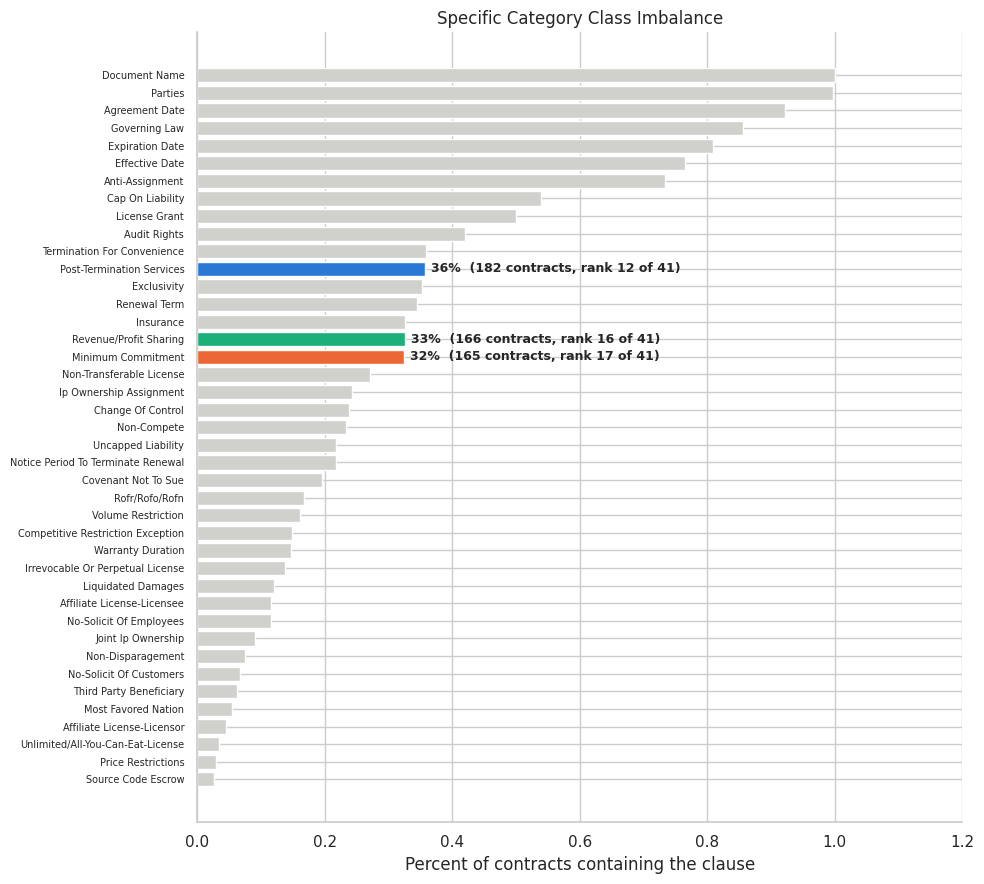

In [ ]:
cat_rates = df_full.groupby("category")["has_clause"].mean().sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(cat_rates.index, cat_rates.values, color=[COLORS.get(c, "#d0d0cc") for c in cat_rates.index])
for i, (c, v) in enumerate(cat_rates.items()):
    if c in FOCUS_CATS:
        n_pos = int(df_full.loc[df_full["category"] == c, "has_clause"].sum())
        ax.text(v + 0.01, i, f"{v:.0%}  ({n_pos} contracts, rank {len(cat_rates) - i} of {len(cat_rates)})",
                va="center", fontsize=9, weight="bold")
ax.tick_params(axis="y", labelsize=7)
ax.set_xlim(0, 1.2)
ax.set_xlabel("Percent of contracts containing the clause")
ax.set_title("Specific Category Class Imbalance")
plt.tight_layout()
plt.show()

## Span Length

This graph shows the average length of the spans of these categories in the contracts that these categories are present in.

**Summary**:
Overall, it seems that the averages are hovering around 50 words, which seems to be about average for all the categories. It is of note, however that this number may be due to the humans that labeled this dataset having a subconcious urge to keep all the categories' span lengths similar. As for our model, this shows that a chunk size of just over 50 words would be optimal to allow our model sufficient context to identify these categories.

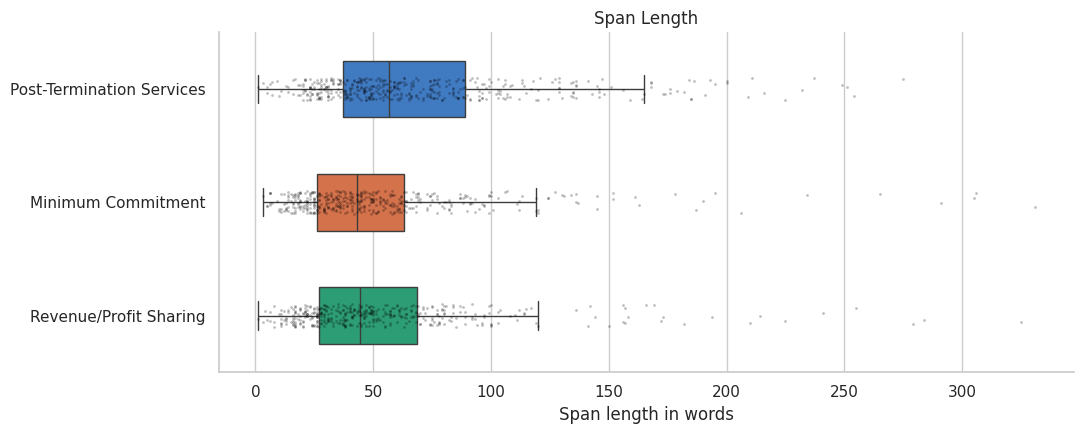

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=focus_spans, y="category", x="words", order=FOCUS_CATS, hue="category",
            palette=COLORS, legend=False, showfliers=False, width=0.5, ax=ax)
sns.stripplot(data=focus_spans, y="category", x="words", order=FOCUS_CATS, color="black",
              size=2, alpha=0.25, ax=ax)
ax.set_xlabel("Span length in words")
ax.set_ylabel("")
ax.set_title("Span Length")
plt.tight_layout()
plt.show()

## Relative Appearances
This graph shows where in a contract each category lies.

**Summary**:
It seems that Minimum Commitment appears typically in the first third of the contract, Revenue/Profit Sharing towards the middle, and Post-Termination Services near the last third. This data can be used to quickly verify the model's outputs to determine if it is drawing data from the right spot, though it will likely need to be used sparingly.

/tmp/ipykernel_5422/1610990667.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


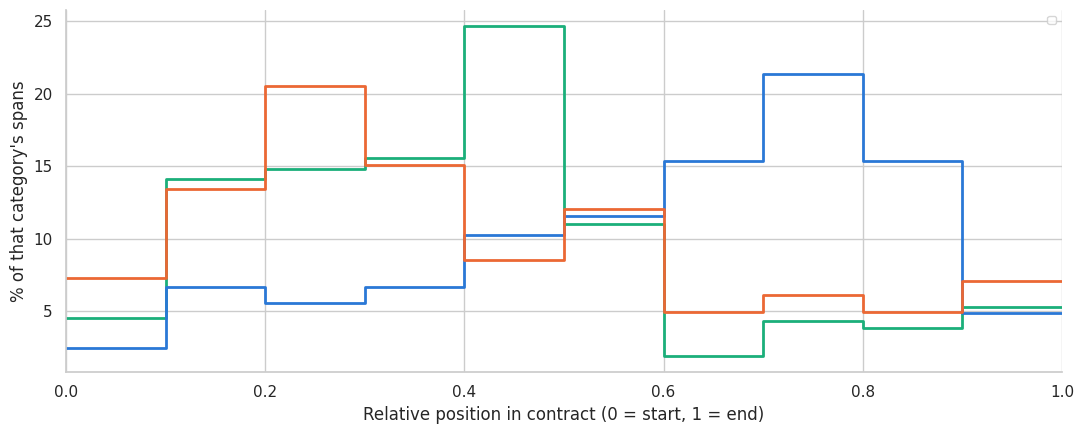

In [ ]:
focus_pos["span_bucket"] = focus_pos["n_spans"].clip(upper=5).astype(str).replace("5", "5+")
bucket_share = (focus_pos.groupby("category")["span_bucket"].value_counts(normalize=True)
                .rename("share").reset_index())

fig, ax = plt.subplots(figsize=(11, 4.5))

sns.histplot(data=focus_spans, x="rel_pos", hue="category", palette=COLORS,
             bins=np.linspace(0, 1, 11), stat="percent", common_norm=False,
             element="step", fill=False, linewidth=2, ax=ax)
ax.set_xlim(0, 1)
ax.set_xlabel("Relative position in contract (0 = start, 1 = end)")
ax.set_ylabel("% of that category's spans")
ax.legend(fontsize=8)
plt.tight_layout();
plt.show()

## Chunking Simulation
These graphs show different percentages of overlap and the percent of spans that would be cut off based on that overlap.

**Summary**:
There is clearly a sharp dip in the beginning for each graph, which follows common intuition, as smaller chunk sizes often lead to more cutoff. However, there doesn't seem to be a clear chunk size or percent overlap that is obviously the correct choice. The greater overlap, as expected, cause less cuts, though it seems that the imrpovements are not too significant, with a maximum of about 10% improvement between no overlap and 10% overlap. Overall, other categories may better inform our chunking strategies.

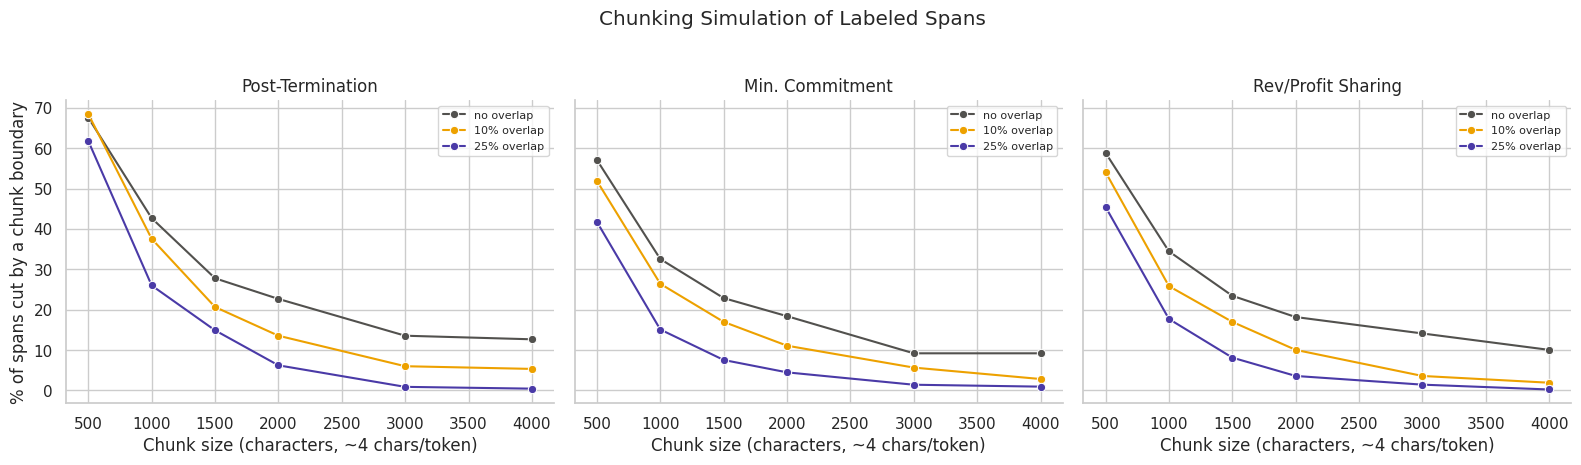

In [ ]:
def pct_split(spans, chunk, overlap):
    """% of spans not fully contained in any sliding-window chunk."""
    stride = chunk - overlap
    s, e = spans["start"].values, spans["end"].values
    k = s // stride
    return 100 * (1 - (e <= k * stride + chunk).mean())

chunk_sizes = [500, 1000, 1500, 2000, 3000, 4000]
overlaps = {"no overlap": 0.0, "10% overlap": 0.10, "25% overlap": 0.25}
chunk_df = pd.DataFrame([
    {"category": cat, "chunk_chars": size, "overlap": name,
     "pct_split": pct_split(focus_spans[focus_spans["category"] == cat], size, int(size * frac))}
    for cat in FOCUS_CATS for size in chunk_sizes for name, frac in overlaps.items()
])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, cat in zip(axes, FOCUS_CATS):
    sns.lineplot(data=chunk_df[chunk_df["category"] == cat], x="chunk_chars", y="pct_split",
                 hue="overlap", marker="o", palette=["#52514e", "#eda100", "#4a3aa7"], ax=ax)
    ax.set_title(SHORT[cat]); ax.set_xlabel("Chunk size (characters, ~4 chars/token)")
    ax.set_ylabel("% of spans cut by a chunk boundary")
    ax.legend(fontsize=8, title="")
fig.suptitle("Chunking Simulation of Labeled Spans", y=1.03)
plt.tight_layout();
plt.show()

## Span Overlap
This graph shows the percent of spans that overlap between the categories of interest and other categories.

**Summary**:
The maximum percent of span overlap is 3%, proving none of these categories should be deleted due to concerns of too much correlation. This proves that we can move forward training our model on these categories.

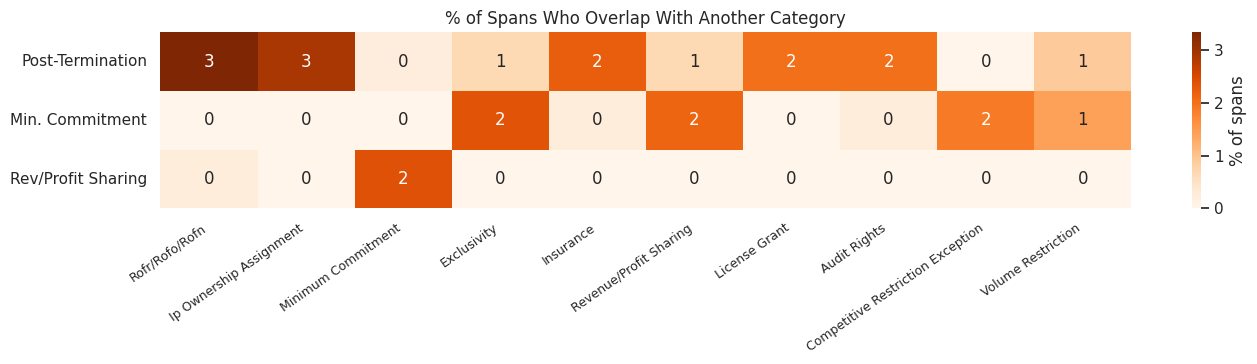

In [ ]:
all_spans = explode_spans(df_full)
spans_by_contract = {t: g[["category", "start", "end"]].values for t, g in all_spans.groupby("contract_title")}

overlap_counts = {cat: Counter() for cat in FOCUS_CATS}
for _, r in focus_spans.iterrows():
    hits = {other for other, s, e in spans_by_contract.get(r["contract_title"], [])
            if other != r["category"] and s < r["end"] and r["start"] < e}
    overlap_counts[r["category"]].update(hits)

span_overlap = (pd.DataFrame(overlap_counts).fillna(0) / focus_spans["category"].value_counts()).T * 100
span_overlap = span_overlap[span_overlap.max().sort_values(ascending=False).head(10).index].rename(index=SHORT)

fig, ax = plt.subplots(figsize=(14, 3.8))
sns.heatmap(span_overlap, annot=True, fmt=".0f", cmap="Oranges", cbar_kws={"label": "% of spans"}, ax=ax)
ax.set_title("% of Spans Who Overlap With Another Category")
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
plt.tight_layout();
plt.show()

## Positive Rate by Contract Type
This graph shows what the expected positive rate of the presence of a certain category based on the contract type.

**Summary**: It seems that certain contracts like Agency and Franchise and Collaboration have a much greater likelihood of the appearance of the contracts versus maintenance or IP. Since the relative frequencies are fairly uniform across the same contract type, there is nothing of concern that we should build into the model based on this data.

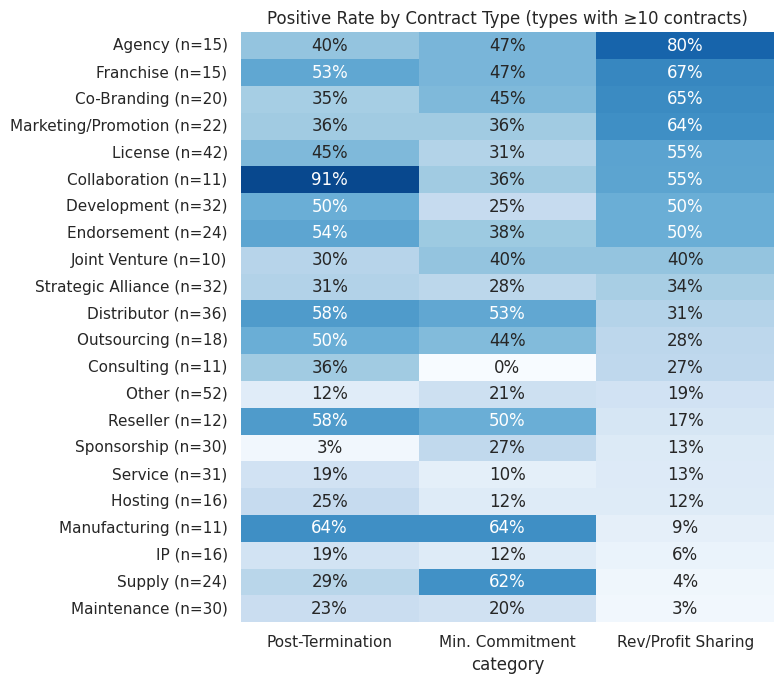

In [ ]:
TYPE_PATTERNS = {
    "License": r"licen[cs]e", "Distributor": r"distribut", "Supply": r"supply",
    "Reseller": r"resell", "Franchise": r"franchise", "Endorsement": r"endorse",
    "Co-Branding": r"co-?brand", "Joint Venture": r"joint venture", "Strategic Alliance": r"alliance",
    "Outsourcing": r"outsourc", "Development": r"develop", "Manufacturing": r"manufactur",
    "Service": r"service", "Agency": r"agency", "Marketing/Promotion": r"marketing|promotion",
    "Sponsorship": r"sponsor", "Hosting": r"hosting", "Maintenance": r"maintenance",
    "Collaboration": r"collaborat", "Consulting": r"consult", "IP": r"\bip\b|intellectual property",
}
def contract_type(title):
    tail = title.split("-")[-1].lower()
    for text in (tail, title.lower()):
        for name, pat in TYPE_PATTERNS.items():
            if re.search(pat, text):
                return name
    return "Other"

focus_df["contract_type"] = focus_df["contract_title"].map(contract_type)
type_n = focus_df.drop_duplicates("contract_title")["contract_type"].value_counts()
type_rate = focus_df.pivot_table(index="contract_type", columns="category", values="has_clause", aggfunc="mean")
type_rate = type_rate.loc[type_n[type_n >= 10].index, FOCUS_CATS]
type_rate.index = [f"{t} (n={type_n[t]})" for t in type_rate.index]
type_rate = type_rate.sort_values("Revenue/Profit Sharing", ascending=False).rename(columns=SHORT)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(type_rate, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title("Positive Rate by Contract Type (types with ≥10 contracts)")
ax.set_ylabel("")
plt.tight_layout();
plt.show()

## Top 20 Keywords
This identifies the top 20 keywords in each document.

**Summary**: The top 20 keywords seem to be fairly expected among all 3 categories of interest. They are all associated with the category and don't overlap between categories. At the high end, searching for the word `termination` has an 85% chance of correctly finding a Post-Termination contract and searching for `minimum` has a 69% chance of finding a Minimum Commitment contract. This provides hints as to what our models may be trained to do.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

N_KEYWORDS = 20
MIN_COVERAGE = 0.05

def clean(text):
    text = re.sub(r"\[\s*\*+\s*\]|\*{3,}", " ", text.lower())
    return re.sub(r"\s+", " ", text)

span_docs = df_full[df_full["has_clause"]].copy()
span_docs["doc"] = span_docs["answer_texts"].map(lambda xs: clean(" ".join(xs)))

vec = CountVectorizer(ngram_range=(1, 2), stop_words="english", binary=True,
                      token_pattern=r"(?u)\b[a-z][a-z]+\b", min_df=5)
X = vec.fit_transform(span_docs["doc"])
vocab = np.array(vec.get_feature_names_out())

keyword_tables = {}
for cat in FOCUS_CATS:
    in_cat = (span_docs["category"] == cat).values
    coverage = np.asarray(X[in_cat].mean(axis=0)).ravel()
    other = np.asarray(X[~in_cat].mean(axis=0)).ravel()
    lift = (coverage + 1e-3) / (other + 1e-3)
    score = coverage * np.log(lift)
    kw = pd.DataFrame({"keyword": vocab, "coverage": coverage, "other_cats": other,
                       "lift": lift, "score": score})
    kw = kw[(kw["coverage"] >= MIN_COVERAGE) & (kw["lift"] > 1)]
    keyword_tables[cat] = kw.sort_values("score", ascending=False).head(N_KEYWORDS).reset_index(drop=True)

keywords_wide = pd.concat(
    {SHORT[c]: t.assign(entry=t["keyword"] + "  (" + (t["coverage"] * 100).round(0).astype(int).astype(str)
                        + "%, " + t["lift"].round(1).astype(str) + "x)")["entry"]
     for c, t in keyword_tables.items()}, axis=1)
keywords_wide.index = keywords_wide.index + 1
display(keywords_wide)

,Post-Termination,Min. Commitment,Rev/Profit Sharing
1,"termination (85%, 10.1x)","minimum (69%, 36.6x)","pay (58%, 20.4x)"
2,"termination agreement (47%, 18.8x)","year (35%, 4.4x)","net (40%, 44.5x)"
3,"expiration (48%, 9.8x)","month (21%, 9.8x)","shall pay (38%, 33.8x)"
4,"termination expiration (26%, 31.7x)","meet (16%, 17.7x)","sales (42%, 19.8x)"
5,"date termination (25%, 27.3x)","annual (18%, 10.6x)","percent (34%, 19.8x)"
6,"expiration agreement (24%, 30.6x)","fails (15%, 15.0x)","revenue (28%, 24.4x)"
7,"continue (34%, 7.5x)","order (18%, 8.1x)","equal (31%, 14.8x)"
8,"inventory (21%, 25.6x)","purchase (20%, 6.3x)","fee (30%, 14.4x)"
9,"expiration termination (21%, 19.1x)","equal (18%, 7.3x)","share (22%, 34.4x)"
10,"period (45%, 3.9x)","dollars (14%, 11.0x)","consideration (24%, 20.9x)"


# Saahi - Category EDA & Cleaning Review

In [ ]:
saahi_categories = ["Cap On Liability", "Uncapped Liability", "Liquidated Damages"]

In [ ]:
saahi_summary = category_split_summary(saahi_categories)
display(saahi_summary.style.format({
    "train_positive_rate": "{:.1%}", "test_positive_rate": "{:.1%}",
    "median_span_words": "{:.1f}", "p95_span_words": "{:.1f}", "max_span_words": "{:.0f}",
}))

,category,train_positive,train_total,train_positive_rate,test_positive,test_total,test_positive_rate,answer_spans,median_span_words,p95_span_words,max_span_words
0,Cap On Liability,222,408,54.4%,53,102,52.0%,672,49.0,136.9,299
1,Uncapped Liability,91,408,22.3%,20,102,19.6%,167,65.0,142.8,262
2,Liquidated Damages,51,408,12.5%,10,102,9.8%,121,49.0,128.0,222


### Class Imbalance

Cap On Liability: 275 positive / 510 total overall (53.9%) — train 222/408 (54.4%), test 53/102 (52.0%)
Uncapped Liability: 111 positive / 510 total overall (21.8%) — train 91/408 (22.3%), test 20/102 (19.6%)
Liquidated Damages: 61 positive / 510 total overall (12.0%) — train 51/408 (12.5%), test 10/102 (9.8%)

All three categories stay fairly consistent between train and test (within 2-3 percentage points each), so unlike some of the rarer categories elsewhere in the dataset, these splits aren't a major concern. Cap On Liability is close to balanced overall; Uncapped Liability and Liquidated Damages are increasingly skewed toward the negative class, with Liquidated Damages having only 10 positive examples in the entire test set. Precision, recall, and F1 should be reported per-category rather than relying on accuracy, especially for Liquidated Damages given how few positive test examples exist to evaluate against.

### Span Length

Cap On Liability: 672 spans, median 49.0 words, p95 136.9 words, max 299 words
Uncapped Liability: 167 spans, median 65.0 words, p95 142.8 words, max 262 words
Liquidated Damages: 121 spans, median 49.0 words, p95 128.0 words, max 222 words

Uncapped Liability tends to run longer than the other two (median 65 words vs. 49), which lines up with what we saw in the actual clause text — these spans are usually full carve-out lists ("nothing shall limit liability for X, Y, Z") rather than a single short sentence. Cap On Liability has by far the most spans relative to positive contracts (672 spans across 275 positive contracts, about 2.4 per contract), consistent with it often being split across multiple linked clauses (the cap itself, plus separate exception clauses) rather than one clean statement.

In [ ]:
for category in saahi_categories:
    print("\n" + "=" * 100)
    raw_examples(category, 5)


CATEGORY: Cap On Liability

Raw example 1:
'Without affecting Section 10 or the respective obligations of the parties under the Confidentiality Agreement and except  for any liability (i) relating to any breach associated with the unauthorized use of Intellectual Property, (ii) arising from the  intentional breach or willful misconduct of a party, or (iii) arising from the non-compliance with any mandatory applicable law or  regulation, the total aggregate liability of one party to another party for any claim relating to any breach of this Agreement (or any  Purchase Order or other agreement entered into in connection with this Agreement) (a "Claim") shall be limited to the aggregate  amount of the purchase prices paid by Distributor to Accuray for Products pursuant to this Agreement (or any Purchase Order or  other Agreement entered into in connection with this Agreement) during the twelve calendar months preceding the date of the  notification to the other party of such Claim less a

In [ ]:
display(formatting_issue_summary(saahi_categories))

,category,spans,contains_newline,repeated_spaces,nonbreaking_space,redaction_marker
0,Cap On Liability,672,28,208,0,29
1,Uncapped Liability,167,8,54,0,14
2,Liquidated Damages,121,7,31,0,8


In [ ]:
rows = []
for category in saahi_categories:
    cat = df_train_cc[(df_train_cc["category"] == category) & (df_train_cc["has_clause"])].copy()
    cat["num_spans"] = cat["answer_texts"].apply(len)
    cat["max_span_words"] = cat["answer_texts"].apply(lambda a: max([len(x.split()) for x in a], default=0))
    rows.append({
        "category": category,
        "positive_contracts": len(cat),
        "contracts_with_multiple_spans": int((cat["num_spans"] > 1).sum()),
        "max_spans_in_one_contract": int(cat["num_spans"].max()),
        "longest_span_words": int(cat["max_span_words"].max()),
        "median_longest_span_words": cat["max_span_words"].median()
    })
display(pd.DataFrame(rows))

,category,positive_contracts,contracts_with_multiple_spans,max_spans_in_one_contract,longest_span_words,median_longest_span_words
0,Cap On Liability,222,131,16,299,73.0
1,Uncapped Liability,91,34,5,262,75.0
2,Liquidated Damages,51,22,10,222,71.0


In [ ]:
saahi_combined = pd.concat([df_train_cc, df_test_cc], ignore_index=True)
saahi_presence = saahi_combined.pivot_table(
    index=["split", "contract_title"], columns="category",
    values="has_clause", aggfunc="max", fill_value=False
).astype(int)

for category in saahi_categories:
    print("\n" + category + ": categories that most often co-occur")
    print(saahi_presence.corr()[category].drop(category).sort_values(ascending=False).head(5).round(2).to_string())


Cap On Liability: categories that most often co-occur
category
Uncapped Liability    0.49
Audit Rights          0.41
Governing Law         0.37
Anti-Assignment       0.37
License Grant         0.35

Uncapped Liability: categories that most often co-occur
category
Cap On Liability            0.49
License Grant               0.34
Non-Transferable License    0.33
Joint Ip Ownership          0.31
Audit Rights                0.29

Liquidated Damages: categories that most often co-occur
category
Post-Termination Services    0.18
Change Of Control            0.18
Minimum Commitment           0.17
Insurance                    0.17
No-Solicit Of Employees      0.17


In [ ]:
for category in saahi_categories:
    print("\n" + "=" * 100)
    print(category)
    print(top_words_for_category(df_train_cc, category))


Cap On Liability
[('party', 573), ('damages', 456), ('agreement', 435), ('s', 348), ('liability', 341), ('other', 326), ('under', 291), ('liable', 234), ('not', 224), ('consequential', 218), ('loss', 212), ('section', 211), ('arising', 206), ('event', 206), ('no', 194), ('breach', 180), ('including', 179), ('special', 176), ('indirect', 171), ('incidental', 161)]

Uncapped Liability
[('party', 326), ('damages', 164), ('section', 143), ('agreement', 141), ('under', 137), ('liability', 130), ('s', 113), ('other', 110), ('obligations', 89), ('except', 84), ('breach', 83), ('arising', 77), ('indemnification', 76), ('not', 71), ('either', 68), ('consequential', 68), ('liable', 66), ('event', 61), ('no', 58), ('special', 58)]

Liquidated Damages
[('termination', 82), ('agreement', 76), ('damages', 71), ('party', 69), ('liquidated', 63), ('pay', 57), ('date', 56), ('fee', 52), ('amount', 43), ('b', 42), ('if', 40), ('not', 36), ('equal', 32), ('event', 30), ('section', 30), ('on', 29), ('s',

### Common Patterns (verified via top_words_for_category)

Cap On Liability — top words: party, damages, agreement, liability, other, liable, consequential, loss, section, arising, event, breach, special, indirect, incidental. Heavy emphasis on exclusion language (consequential, indirect, incidental, special) alongside the core liability/damages vocabulary.

Uncapped Liability — top words: party, damages, section, agreement, under, liability, other, obligations, except, breach, arising, indemnification, either, consequential. Notably includes "indemnification" and "except" at high frequency — consistent with these spans functioning as carve-outs from a cap rather than standalone statements.

Liquidated Damages — top words: termination, agreement, damages, party, liquidated, pay, date, fee, amount, equal, event, months. Distinctly different vocabulary from the other two — centers on payment mechanics (pay, fee, amount, equal) and timing (date, months) rather than exclusion/limitation language.

### Cleaning Issues (verified via formatting_issue_summary)

Cap On Liability: 672 spans — 28 contain newlines, 208 have repeated spaces, 0 nonbreaking spaces, 29 contain redaction markers.
Uncapped Liability: 167 spans — 8 contain newlines, 54 have repeated spaces, 0 nonbreaking spaces, 14 contain redaction markers.
Liquidated Damages: 121 spans — 7 contain newlines, 31 have repeated spaces, 0 nonbreaking spaces, 8 contain redaction markers.

Repeated spaces are the dominant issue across all three (roughly 30% of Cap On Liability spans), consistent with the PDF-to-text whitespace artifacts found earlier in the broader dataset exploration. Redaction markers appear in 4-7% of spans for each category, confirming dollar amounts are frequently hidden regardless of which liability category is involved.

### Ambiguous / Unusual Cases

Several Liquidated Damages spans don't contain the phrase "liquidated damages" at all despite being labeled positive — e.g., one example is a reimbursement-of-expenses clause tied to a terminated transaction, another is a royalty-rate adjustment clause. This suggests some annotation inconsistency where the category was applied to general "payment owed upon an event" language rather than strictly liquidated-damages provisions.

The Cap On Liability / Uncapped Liability overlap isn't just correlational — it's literal. Example 1 for both categories is the identical sentence (the Accuray/Distributor liability clause), directly confirming the 87-contract exact-span overlap found in the quantitative check above.

In [ ]:
saahi_combined = pd.concat([df_train_cc, df_test_cc], ignore_index=True)

for category in saahi_categories:
    mine = saahi_combined[saahi_combined["category"] == category].set_index(["split", "contract_title"])["answer_texts"]
    shared = {}
    for other in saahi_combined["category"].unique():
        if other == category:
            continue
        theirs = saahi_combined[saahi_combined["category"] == other].set_index(["split", "contract_title"])["answer_texts"]
        n = sum(bool(set(spans) & set(theirs.get(key, []))) for key, spans in mine.items() if spans)
        if n:
            shared[other] = n
    print("\n" + category + ": contracts where the exact same span is also labeled as another category:")
    print(sorted(shared.items(), key=lambda x: -x[1])[:5])


Cap On Liability: contracts where the exact same span is also labeled as another category:
[('Uncapped Liability', 87), ('Warranty Duration', 7), ('Liquidated Damages', 3), ('Covenant Not To Sue', 2), ('Minimum Commitment', 1)]

Uncapped Liability: contracts where the exact same span is also labeled as another category:
[('Cap On Liability', 87), ('Covenant Not To Sue', 1)]

Liquidated Damages: contracts where the exact same span is also labeled as another category:
[('Change Of Control', 4), ('Termination For Convenience', 4), ('Cap On Liability', 3), ('Minimum Commitment', 2), ('No-Solicit Of Employees', 2)]


### Exact Span Overlap

Cap On Liability: shares exact spans with Uncapped Liability in 87 contracts, Warranty Duration in 7, Liquidated Damages in 3, Covenant Not To Sue in 2, Minimum Commitment in 1.

Uncapped Liability: shares exact spans with Cap On Liability in 87 contracts, Covenant Not To Sue in 1.

Liquidated Damages: shares exact spans with Change Of Control in 4 contracts, Termination For Convenience in 4, Cap On Liability in 3, Minimum Commitment in 2, No-Solicit Of Employees in 2.

The Cap On Liability / Uncapped Liability overlap is dramatic and confirms what the earlier qualitative review suggested: in 87 contracts, annotators labeled the exact same sentence as both categories rather than treating them as mutually exclusive. This is a much stronger signal than simple co-occurrence — it means the dataset itself blurs the line between "there is a cap" and "here's what's excluded from the cap," which has real implications for how these two should be modeled (as a linked pair rather than fully independent labels). Liquidated Damages shows weaker, more scattered overlap, mostly small numbers spread across several unrelated categories rather than one dominant pairing — consistent with it being a more standalone concept.

In [ ]:
rows = []
for category in saahi_categories:
    cat = df_train_cc[(df_train_cc["category"] == category) & (df_train_cc["has_clause"])].copy()
    cat["num_spans"] = cat["answer_texts"].apply(len)
    cat["max_span_words"] = cat["answer_texts"].apply(lambda a: max([len(x.split()) for x in a], default=0))
    rows.append({
        "category": category,
        "positive_contracts": len(cat),
        "contracts_with_multiple_spans": int((cat["num_spans"] > 1).sum()),
        "max_spans_in_one_contract": int(cat["num_spans"].max()),
        "longest_span_words": int(cat["max_span_words"].max()),
        "median_longest_span_words": cat["max_span_words"].median()
    })
display(pd.DataFrame(rows))

,category,positive_contracts,contracts_with_multiple_spans,max_spans_in_one_contract,longest_span_words,median_longest_span_words
0,Cap On Liability,222,131,16,299,73.0
1,Uncapped Liability,91,34,5,262,75.0
2,Liquidated Damages,51,22,10,222,71.0


### Multiple Spans & Outliers

Cap On Liability: 222 positive contracts, 131 (59%) have multiple spans, max 16 spans in one contract, longest span 299 words, median longest-span length 73 words.
Uncapped Liability: 91 positive contracts, 34 (37%) have multiple spans, max 5 spans in one contract, longest span 262 words, median longest-span length 75 words.
Liquidated Damages: 51 positive contracts, 22 (43%) have multiple spans, max 10 spans in one contract, longest span 222 words, median longest-span length 71 words.

Cap On Liability stands out here — nearly 60% of its positive contracts have more than one labeled span, and one contract has as many as 16 separate spans for this single category. This is the strongest evidence yet that Cap On Liability clauses are rarely self-contained: they're typically broken across the core limitation plus multiple separate exception/exclusion clauses, which fits directly with the chunking risk already flagged above. Uncapped Liability has the lowest rate of multiple spans (37%) despite having the longest median span — consistent with it usually appearing as one dense carve-out list rather than several scattered mentions.

## Risk Label & Visualization: 19 Categories

In [ ]:
print(sorted(imb.index.tolist()))

['Affiliate License-Licensee', 'Affiliate License-Licensor', 'Agreement Date', 'Anti-Assignment', 'Audit Rights', 'Cap On Liability', 'Change Of Control', 'Competitive Restriction Exception', 'Covenant Not To Sue', 'Document Name', 'Effective Date', 'Exclusivity', 'Expiration Date', 'Governing Law', 'Insurance', 'Ip Ownership Assignment', 'Irrevocable Or Perpetual License', 'Joint Ip Ownership', 'License Grant', 'Liquidated Damages', 'Minimum Commitment', 'Most Favored Nation', 'No-Solicit Of Customers', 'No-Solicit Of Employees', 'Non-Compete', 'Non-Disparagement', 'Non-Transferable License', 'Notice Period To Terminate Renewal', 'Parties', 'Post-Termination Services', 'Price Restrictions', 'Renewal Term', 'Revenue/Profit Sharing', 'Rofr/Rofo/Rofn', 'Source Code Escrow', 'Termination For Convenience', 'Third Party Beneficiary', 'Uncapped Liability', 'Unlimited/All-You-Can-Eat-License', 'Volume Restriction', 'Warranty Duration']


In [ ]:
kept_categories = [
    "Cap On Liability", "Uncapped Liability", "Liquidated Damages", "Insurance",
    "Warranty Duration", "Anti-Assignment", "Change Of Control", "Renewal Term",
    "Notice Period To Terminate Renewal", "Termination For Convenience",
    "Post-Termination Services", "License Grant", "Ip Ownership Assignment",
    "Non-Transferable License", "Non-Compete", "Exclusivity",
    "Minimum Commitment", "Revenue/Profit Sharing", "Audit Rights"
]

kept_summary = imb.loc[kept_categories, ["n", "positives", "negatives", "pos_rate"]].round(3)
display(kept_summary.sort_values("pos_rate", ascending=False))

,n,positives,negatives,pos_rate
category,,,,
Anti-Assignment,510,374,136,0.733
Cap On Liability,510,275,235,0.539
License Grant,510,255,255,0.500
Audit Rights,510,214,296,0.420
Termination For Convenience,510,183,327,0.359
Post-Termination Services,510,182,328,0.357
Exclusivity,510,180,330,0.353
Renewal Term,510,176,334,0.345
Insurance,510,166,344,0.325


In [ ]:
for category in ["License Grant", "IP Ownership Assignment", "Non-Transferable License", "Non-Compete", "Exclusivity"]:
    print("\n" + "=" * 100)
    print(category)
    print(top_words_for_category(df_train_cc, category))


License Grant
[('use', 592), ('license', 530), ('non', 462), ('agreement', 451), ('grants', 393), ('exclusive', 388), ('right', 359), ('hereby', 340), ('s', 299), ('products', 243), ('subject', 238), ('other', 223), ('under', 219), ('licensed', 215), ('royalty', 206), ('free', 190), ('its', 190), ('terms', 190), ('section', 189), ('software', 170)]

IP Ownership Assignment
[]

Non-Transferable License
[('non', 302), ('use', 210), ('agreement', 206), ('license', 180), ('grants', 148), ('exclusive', 143), ('hereby', 123), ('right', 122), ('transferable', 118), ('except', 107), ('s', 104), ('software', 97), ('subject', 96), ('royalty', 85), ('company', 84), ('terms', 83), ('free', 81), ('solely', 80), ('licensed', 78), ('section', 77)]

Non-Compete
[('not', 176), ('agreement', 142), ('business', 115), ('products', 100), ('other', 92), ('company', 89), ('during', 86), ('on', 85), ('which', 81), ('its', 81), ('will', 75), ('term', 71), ('party', 71), ('s', 69), ('directly', 69), ('product'

In [ ]:
import re

dimension_patterns = {
    "Money":    r"\b(uncapped|unlimited|without limit|no limit|not limited|indemnif|penalt|liquidated damages|exceed|punitive|minimum|commitment|royalty|fee|revenue|profit|share)\b",
    "Stuck":    r"\b(perpetual|irrevocable|automatically renew|non-cancellable|non-cancelable|cannot be terminated|evergreen|successive|term of this agreement|duration)\b",
    "Fair":     r"\b(sole discretion|at its sole|without cause|unilaterally|either party|mutual|audit|inspect|examine)\b",
    "Big Deal": r"\b(entire agreement|terminate this agreement|worldwide|exclusively|sole and exclusive|change of control|entire business|compete|competitive|restrict|territory|market)\b",
}

def dimension_hit_rate(category, pattern):
    spans = df_train_cc.loc[
        (df_train_cc["category"] == category) & (df_train_cc["has_clause"]),
        "answer_texts"
    ].explode().dropna()
    if len(spans) == 0:
        return 0.0
    hits = spans.str.contains(pattern, case=False, regex=True)
    return hits.mean()

rows = []
for category in kept_categories:
    row = {"category": category}
    for dim, pattern in dimension_patterns.items():
        row[dim] = dimension_hit_rate(category, pattern)
    rows.append(row)

hit_rates_df = pd.DataFrame(rows).set_index("category").round(3)
display(hit_rates_df.sort_values("Money", ascending=False))

/tmp/ipykernel_5422/439845816.py:17: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hits = spans.str.contains(pattern, case=False, regex=True)


,Money,Stuck,Fair,Big Deal
category,,,,
Liquidated Damages,0.808,0.010,0.048,0.115
Revenue/Profit Sharing,0.666,0.026,0.019,0.087
Minimum Commitment,0.658,0.060,0.028,0.103
Uncapped Liability,0.500,0.000,0.387,0.021
Cap On Liability,0.419,0.009,0.172,0.074
Non-Transferable License,0.364,0.190,0.012,0.368
License Grant,0.334,0.243,0.013,0.436
Exclusivity,0.149,0.097,0.020,0.489
Post-Termination Services,0.132,0.063,0.071,0.134


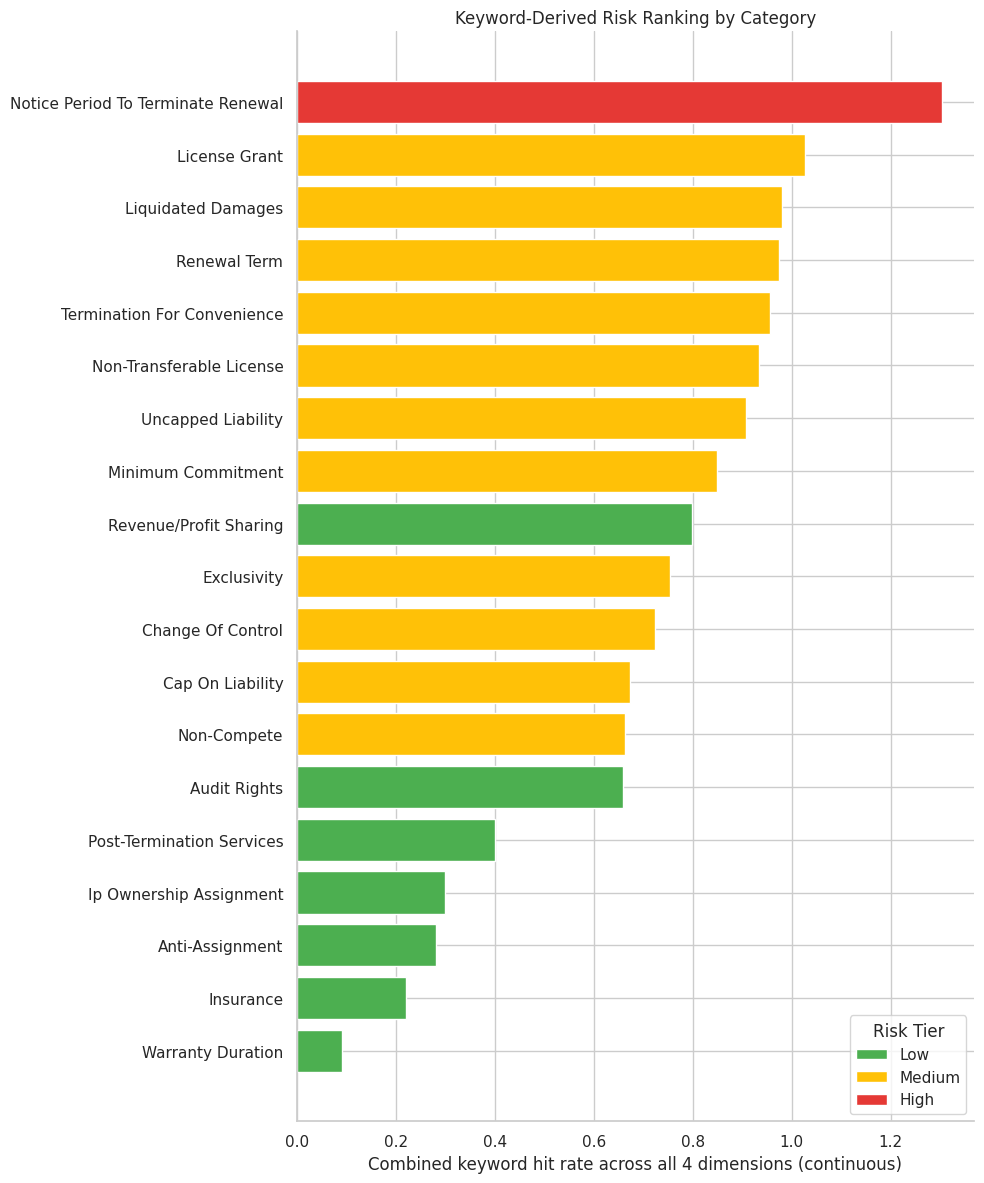

,Money,Stuck,Fair,Big Deal,Raw_Total,Total,Risk Tier
category,,,,,,,
Notice Period To Terminate Renewal,0,2,2,1,1.303,5,High
License Grant,1,1,0,2,1.026,4,Medium
Liquidated Damages,2,0,0,1,0.981,3,Medium
Renewal Term,0,2,1,0,0.975,3,Medium
Termination For Convenience,0,0,1,2,0.957,3,Medium
Non-Transferable License,1,1,0,1,0.934,3,Medium
Uncapped Liability,2,0,1,0,0.908,3,Medium
Minimum Commitment,2,0,0,1,0.849,3,Medium
Revenue/Profit Sharing,2,0,0,0,0.798,2,Low


In [ ]:
scored_df["Raw_Total"] = hit_rates_df[["Money", "Stuck", "Fair", "Big Deal"]].sum(axis=1)
scored_df = scored_df.sort_values("Raw_Total", ascending=False)

fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(
    scored_df.index[::-1],
    scored_df["Raw_Total"][::-1],
    color=[risk_colors[t] for t in scored_df["Risk Tier"][::-1]]
)
ax.set_xlabel("Combined keyword hit rate across all 4 dimensions (continuous)")
ax.set_title("Keyword-Derived Risk Ranking by Category")

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=risk_colors[t], label=t) for t in ["Low", "Medium", "High"]]
ax.legend(handles=legend_elements, title="Risk Tier", loc="lower right")
plt.tight_layout(); plt.show()

display(scored_df[["Money", "Stuck", "Fair", "Big Deal", "Raw_Total", "Total", "Risk Tier"]])

In [ ]:
$print(len(scored_df))
print(scored_df.index.tolist())

19
['Notice Period To Terminate Renewal', 'License Grant', 'Cap On Liability', 'Liquidated Damages', 'Uncapped Liability', 'Renewal Term', 'Change Of Control', 'Exclusivity', 'Non-Compete', 'Non-Transferable License', 'Termination For Convenience', 'Minimum Commitment', 'Revenue/Profit Sharing', 'Audit Rights', 'Post-Termination Services', 'Insurance', 'Anti-Assignment', 'Ip Ownership Assignment', 'Warranty Duration']
